# Presentation Charts â€” IEEE 9-Bus RL + SCED

Produces publication-quality figures (12pt font at 8.5Ã—11") from the same
results directory as `inspect_rl_results.ipynb`.

In [67]:
# â”€â”€ Shared setup (identical config to inspect_rl_results.ipynb) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import sys, os, importlib
from datetime import timedelta, datetime as _dt

import numpy as np
import pandas as pd
import yaml
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors

# â”€â”€ Presentation font sizes â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Target: 12pt body text when figure is pasted at ~6" wide in an 8.5Ã—11" doc.
# Figures are created at actual print size so matplotlib pt = printed pt.
FONT_BODY   = 12
FONT_TITLE  = 13
FONT_SUPTITLE = 14
FONT_TICK   = 10
FONT_LEGEND = 9
SAVE_DPI    = 300   # high res for print

FIG_W = 6.0    # inches â€” target width in document

matplotlib.rcParams.update({
    'font.size':        FONT_BODY,
    'axes.titlesize':   FONT_TITLE,
    'axes.labelsize':   FONT_BODY,
    'xtick.labelsize':  FONT_TICK,
    'ytick.labelsize':  FONT_TICK,
    'legend.fontsize':  FONT_LEGEND,
    'figure.titlesize': FONT_SUPTITLE,
    'figure.dpi':       SAVE_DPI,
    'savefig.dpi':      SAVE_DPI,
    'savefig.bbox':     'tight',
    'lines.linewidth':  1.5,
    'lines.markersize': 4,
    'axes.linewidth':   0.8,
    'grid.linewidth':   0.5,
})

# â”€â”€ Path setup â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
testbed_dir = os.path.abspath('.')
repo_root = os.path.abspath('..')
for p in [testbed_dir, repo_root]:
    if p not in sys.path:
        sys.path.insert(0, p)

from ieee9_network import build_ieee9_network
from clearing.sced_clearing import clear_sced

import nodal_plot
importlib.reload(nodal_plot)
from nodal_plot import (
    plot_nodal_circlize, plot_network_topology,
    assign_bus_colors, compute_ptdf_flows,
    BUS_PALETTE, TRANSIT_COLOR, _darken,
)

# â”€â”€ CONFIG (same as inspect_rl_results) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
SCENARIO = 'base_profit_matd3'  # 'base_profit_matd3', 'base_profit_sac', 'base', 'congested', 'withholding', 'heavy_congestion'
FINAL_DIR = '../testbed_results/rl_final/ieee9_rl_egret_sced'
PLOT_HOUR = 12
FOCUS_AGENT = None

# Load scenario config
with open('scenarios.yaml') as f:
    all_scenarios = yaml.safe_load(f)
assert SCENARIO in all_scenarios
scenario_cfg = all_scenarios[SCENARIO]
scenario_name = scenario_cfg['name']
line_overrides = scenario_cfg.get('line_overrides', {})

ALGORITHM = scenario_cfg.get('training', {}).get('algorithm', 'matd3')
RESULTS_DIR = '../' + scenario_cfg.get('training', {}).get('results_dir', f'testbed_results/rl_{ALGORITHM}')

# Load bid history
bids_df = pd.read_csv(f'{RESULTS_DIR}/bid_history.csv', parse_dates=['timestamp'])
bids_df['hour'] = bids_df['timestamp'].dt.hour
RL_AGENTS = sorted(bids_df['unit_id'].unique())

if FOCUS_AGENT is None:
    FOCUS_AGENT = RL_AGENTS[0]

# Network metadata
_network = build_ieee9_network(periods=1)
_gen_df = _network.generators
gen_mc = {name: float(row['marginal_cost']) for name, row in _gen_df.iterrows()}
gen_bus = {name: str(row['bus']) for name, row in _gen_df.iterrows()}
gen_capacity = {name: float(row['p_nom']) for name, row in _gen_df.iterrows()}
RL_GENERATORS = set(RL_AGENTS)
MC = {u: gen_mc[u] for u in RL_AGENTS}

UNIT_COLORS = {}
for i, unit in enumerate(RL_AGENTS):
    bus = gen_bus[unit]
    bus_idx = sorted(_gen_df['bus'].unique()).index(bus)
    UNIT_COLORS[unit] = BUS_PALETTE[bus_idx % len(BUS_PALETTE)]

# Bid type handling
raw_types = set(bids_df['bid_type'].unique())
if raw_types == {'pmin'}:
    bids_df['bid_type'] = 'single'
    raw_types = {'single'}
SINGLE_BID_MODE = 'single' in raw_types and 'flex' not in raw_types
if SINGLE_BID_MODE:
    primary_bids = bids_df.copy()
    BID_LABEL = 'Bid'
else:
    primary_bids = bids_df[bids_df['bid_type'] == 'flex'].copy()
    BID_LABEL = 'Flex Bid'

n_agents = len(RL_AGENTS)
print(f'Scenario: {scenario_name}  |  Algorithm: {ALGORITHM}  |  Results: {RESULTS_DIR}')
print(f'RL agents: {RL_AGENTS}  |  Bid mode: {"single" if SINGLE_BID_MODE else "2-part"}')
print(f'Figure target: {FIG_W}" wide at {SAVE_DPI} dpi')

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
Scenario: Base Case — Pure Profit Reward  |  Algorithm: matd3  |  Results: ../testbed_results/rl_matd3
RL agents: ['gen_0']  |  Bid mode: single
Figure target: 6.0" wide at 300 dpi


## Chart 0 — IEEE 9-Bus Network (Clean Topology)

Static network diagram showing generators, loads, and line capacities at H12.
No dispatch results — just the physical system for the intro section.

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
INFO:learning_runner:Added generator 'gen_peaker_0': bus=1, p_max=50.0, price=60.0
INFO:learning_runner:Generator overrides applied: gen_0($35, 300MW), gen_1($50, 270MW), gen_slack_0($20, 250MW), gen_peaker_0($60, 50MW)
INFO:learning_runner:Line overrides applied: line_0(250MW), line_1(250MW), line_2(150MW), line_3(300MW), line_4(150MW), line_5(250MW), line_6(250MW), line_7(250MW), line_8(250MW)


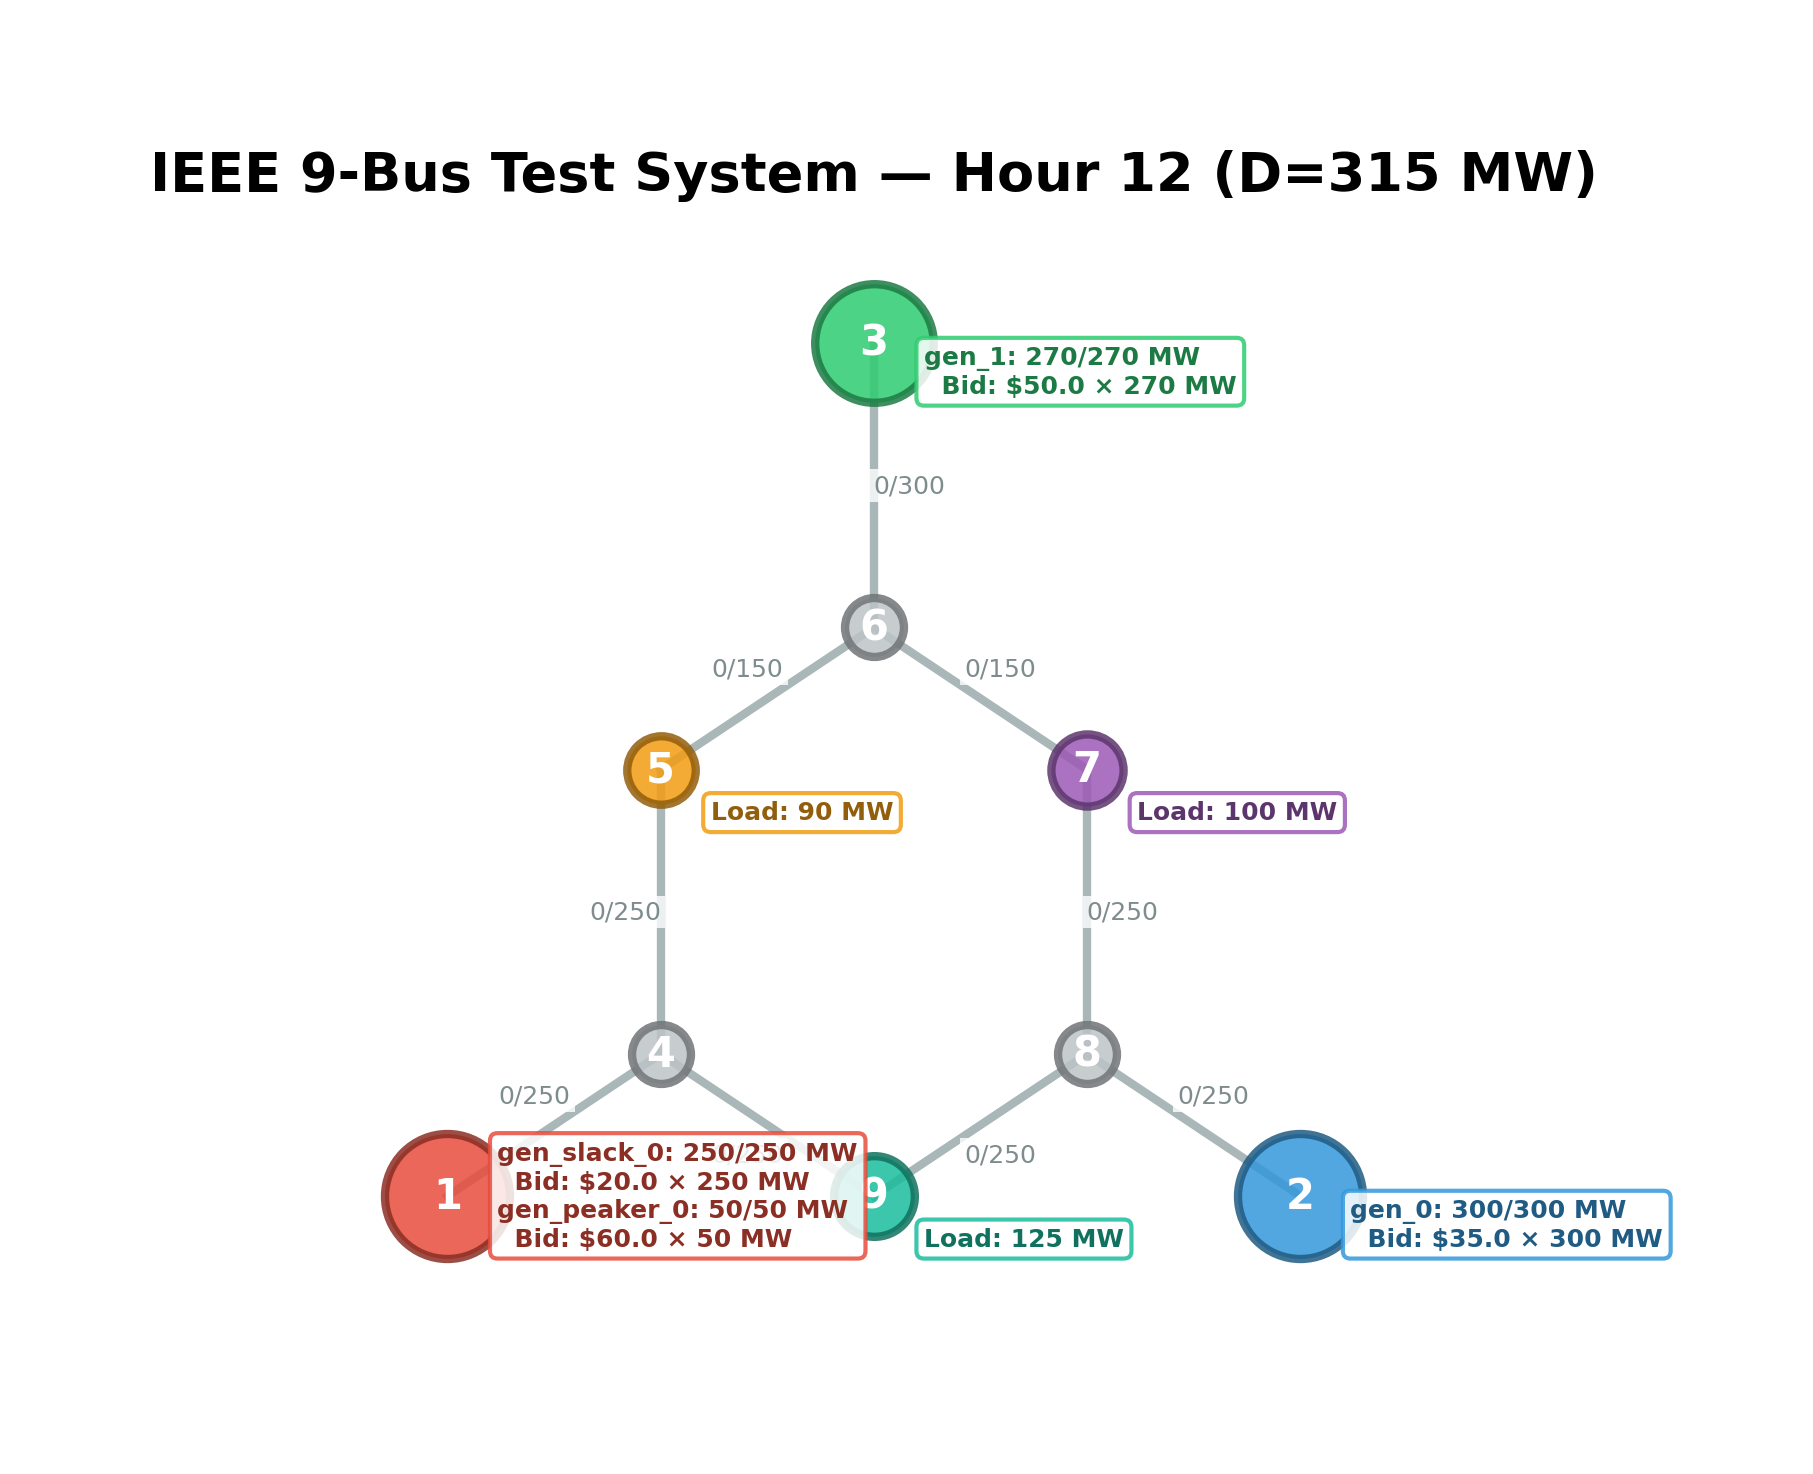

Saved: ../testbed_results/rl_matd3/pres_network_clean.png


In [68]:
# ── Clean IEEE 9-Bus topology (no dispatch) ─────────────────────────────────
#
# Shows: generators (nameplate MW + MC), loads (H12 demand), line capacities.
# Does NOT show: dispatch, bids, LMPs, line flows.

_pcfg_intro = scenario_cfg.get("profile", {})
_net_intro = build_ieee9_network(start="2025-01-01", periods=24, profile_cfg=_pcfg_intro)

# Apply generator overrides from scenario
from learning_runner import _apply_generator_overrides, _apply_line_overrides
_apply_generator_overrides(_net_intro, scenario_cfg.get("generators", {}))
_apply_line_overrides(_net_intro, scenario_cfg.get("line_overrides", {}))

# Build supply_by_bus with nameplate capacity only (no dispatch)
_gen_intro = _net_intro.generators
_all_buses_intro = sorted(_net_intro.buses.index.tolist(), key=lambda x: int(x))

supply_intro = {}
for gname, grow in _gen_intro.iterrows():
    bus = str(grow["bus"])
    if bus not in supply_intro:
        supply_intro[bus] = []
    supply_intro[bus].append({
        "unit_id": gname,
        "price": float(grow["marginal_cost"]),
        "volume": float(grow["p_nom"]),      # nameplate = offered
        "accepted_volume": float(grow["p_nom"]),  # = capacity (clean view)
        "capacity": float(grow["p_nom"]),
    })
for bus in supply_intro:
    supply_intro[bus].sort(key=lambda g: g["price"])

# Build demand_by_bus at PLOT_HOUR
demand_intro = {}
for lname in _net_intro.loads.index:
    bus = str(_net_intro.loads.at[lname, "bus"])
    ts = _net_intro.snapshots[PLOT_HOUR]
    if lname in _net_intro.loads_t.p_set.columns:
        d = float(_net_intro.loads_t.p_set.at[ts, lname])
    else:
        d = float(_net_intro.loads.at[lname, "p_set"])
    demand_intro[bus] = demand_intro.get(bus, 0) + d

colors_intro = assign_bus_colors(_all_buses_intro, supply_intro, demand_intro)

total_demand = sum(demand_intro.values())
fig_intro, ax_intro = plot_network_topology(
    _net_intro,
    supply_by_bus=supply_intro,
    demand_by_bus=demand_intro,
    bus_colors=colors_intro,
    bus_lmps=None,               # no LMPs
    demand_served_by_bus=None,    # no served info
    line_flows={},               # empty dict = no flow arrows
    title=f"IEEE 9-Bus Test System — Hour {PLOT_HOUR} (D={total_demand:.0f} MW)",
)
fig_intro.set_size_inches(FIG_W, FIG_W * 0.8)
fig_intro.savefig(f"{RESULTS_DIR}/pres_network_clean.png", bbox_inches="tight")
plt.show()
print(f"Saved: {RESULTS_DIR}/pres_network_clean.png")


## Chart 1 â€” Reward Surface (Optimization Landscape)

From original cell 5.

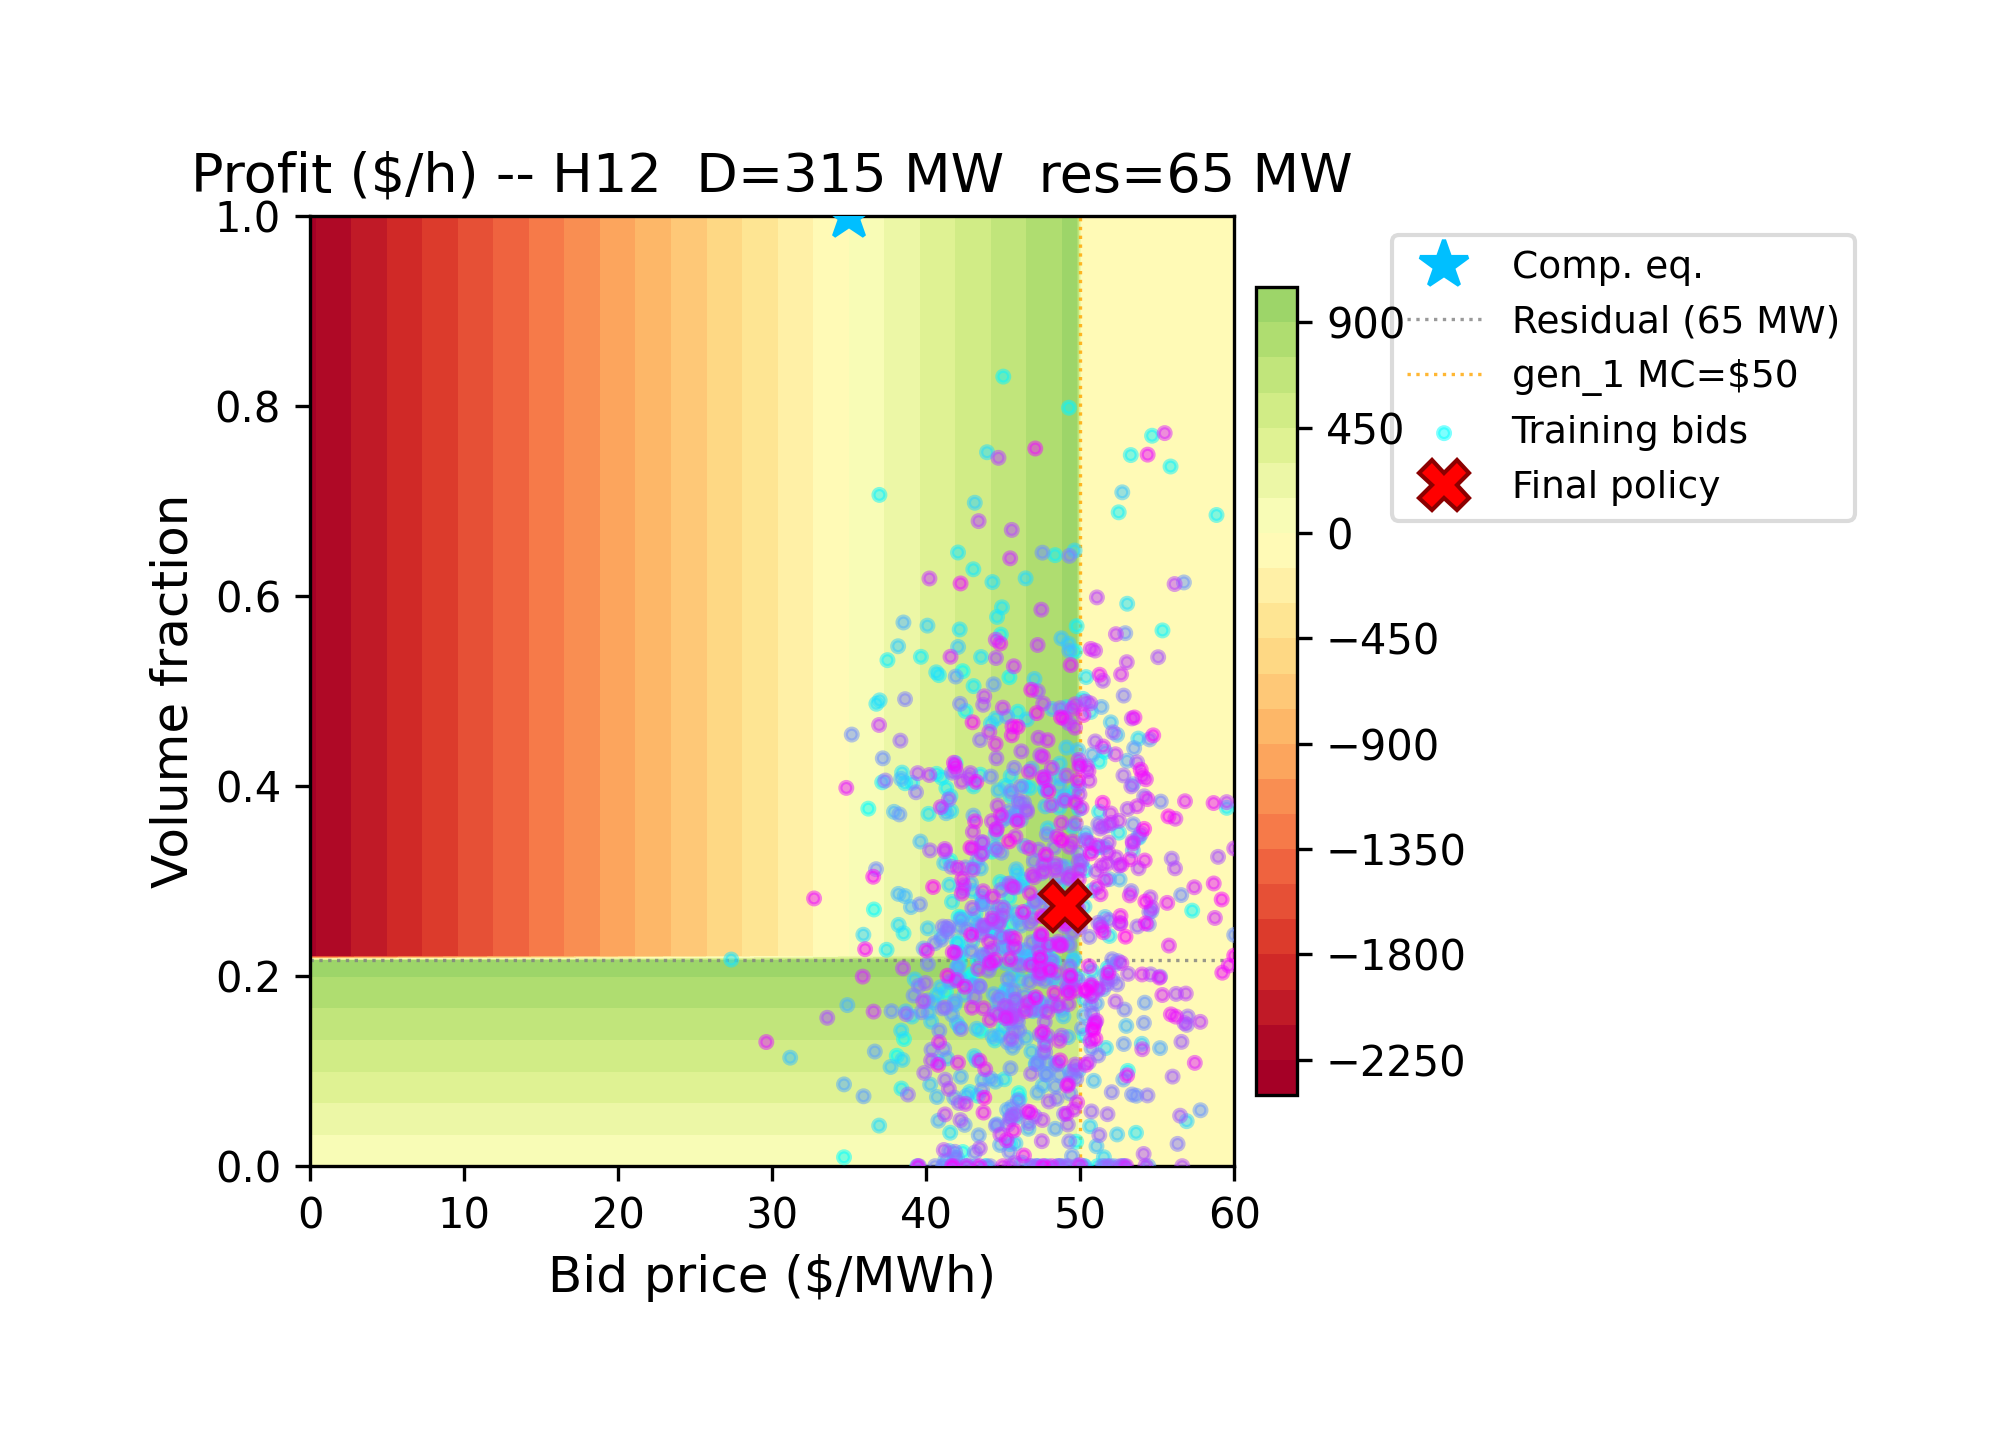

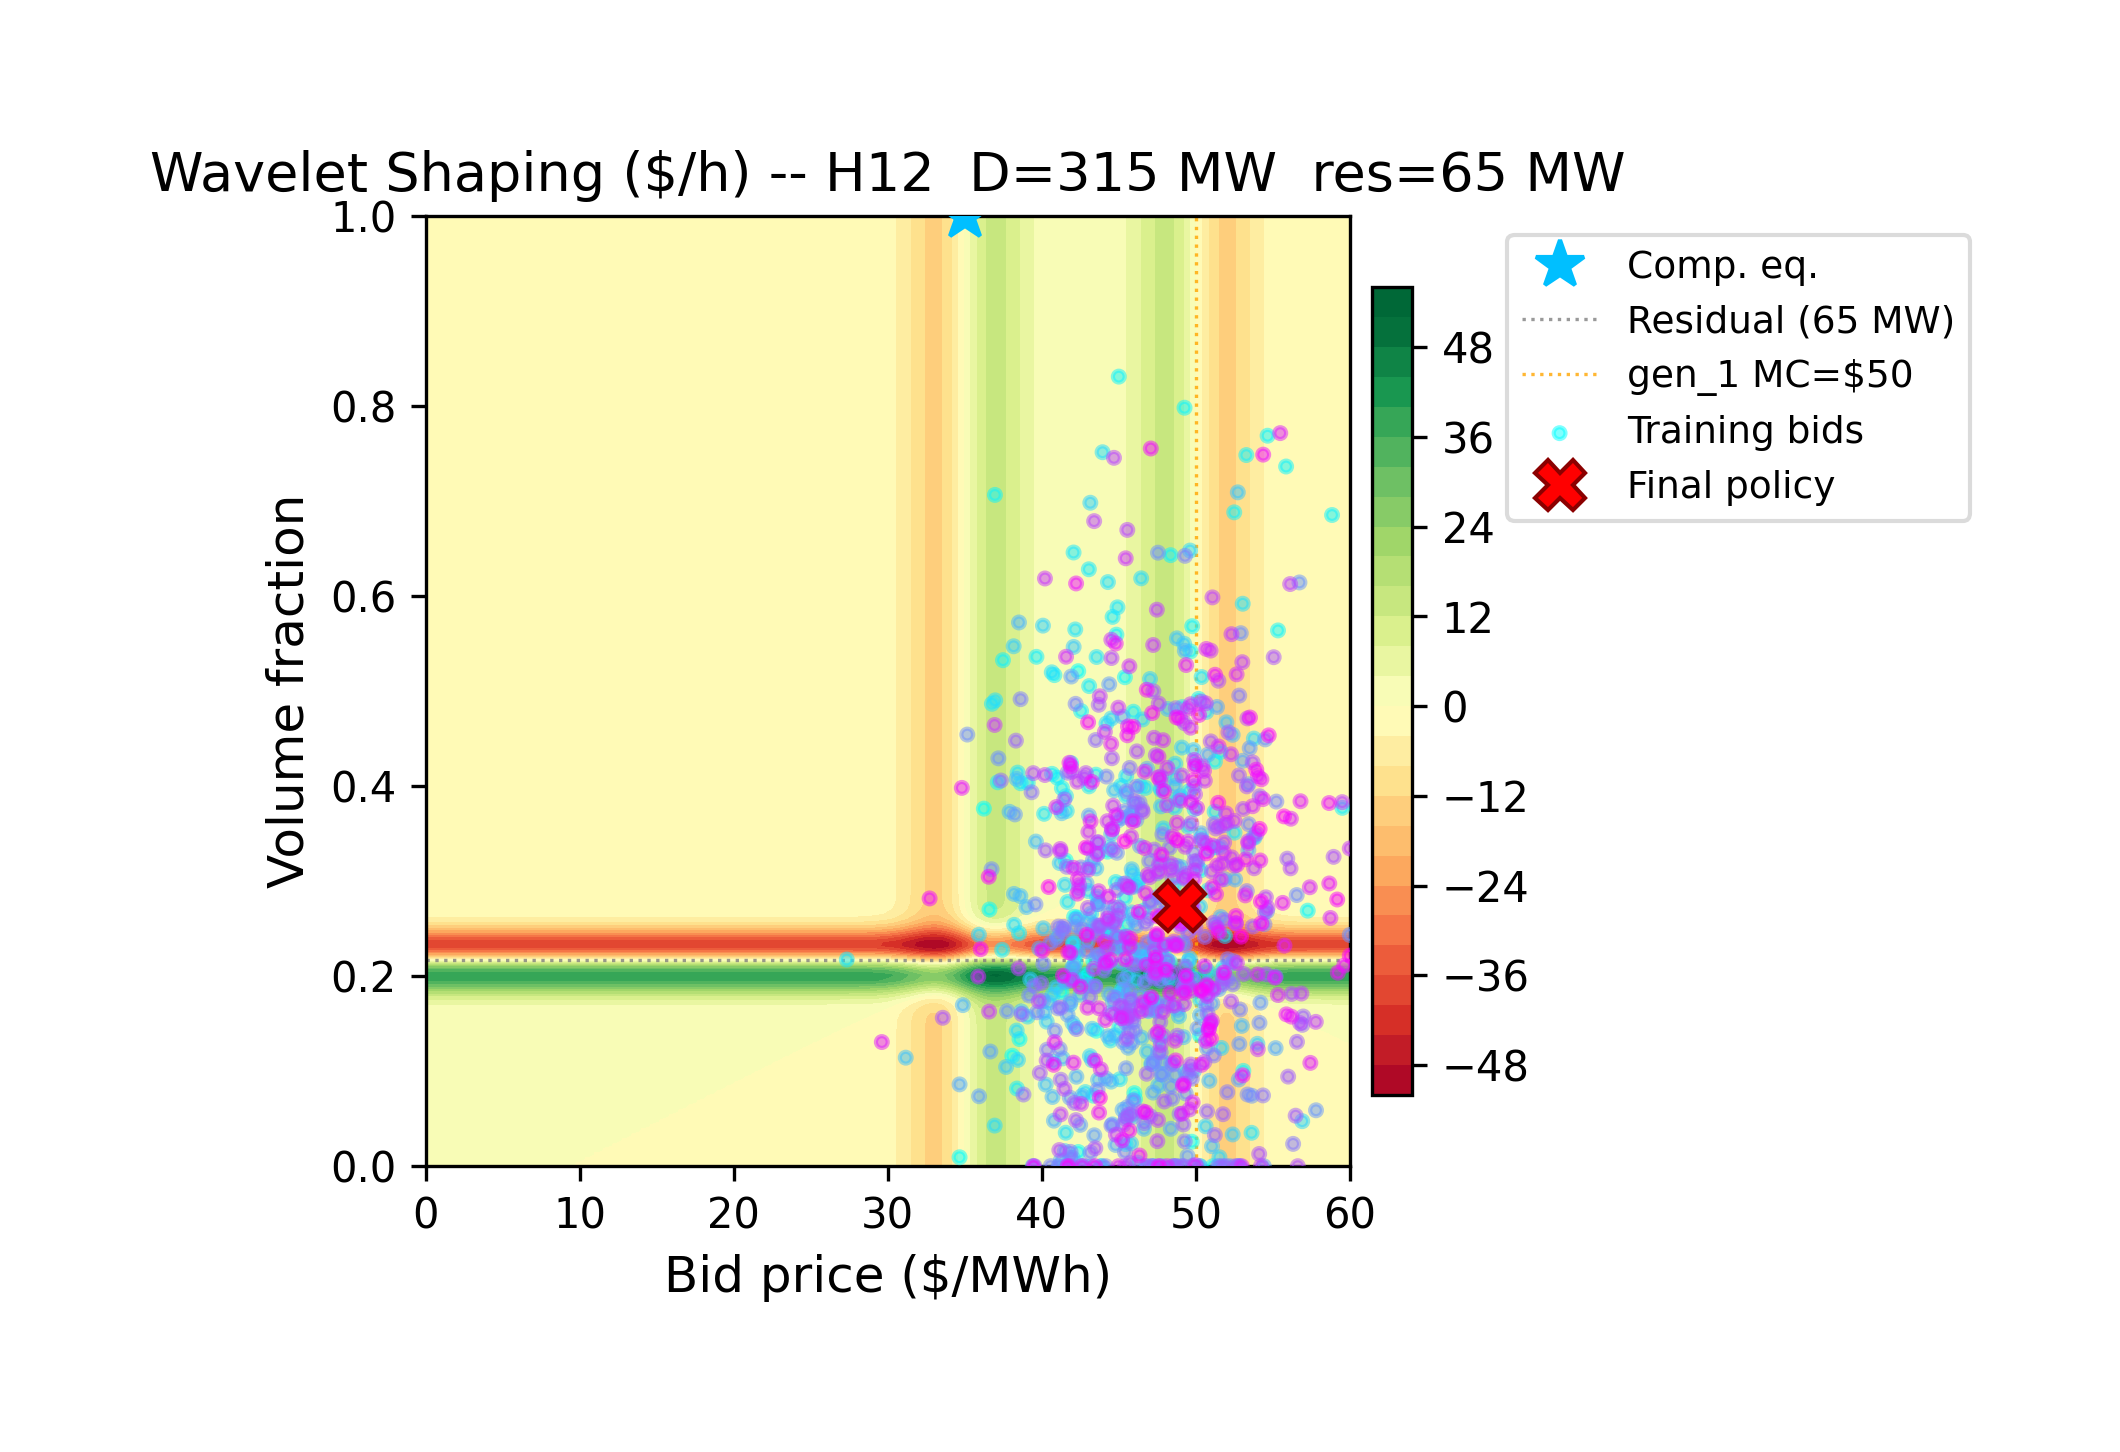

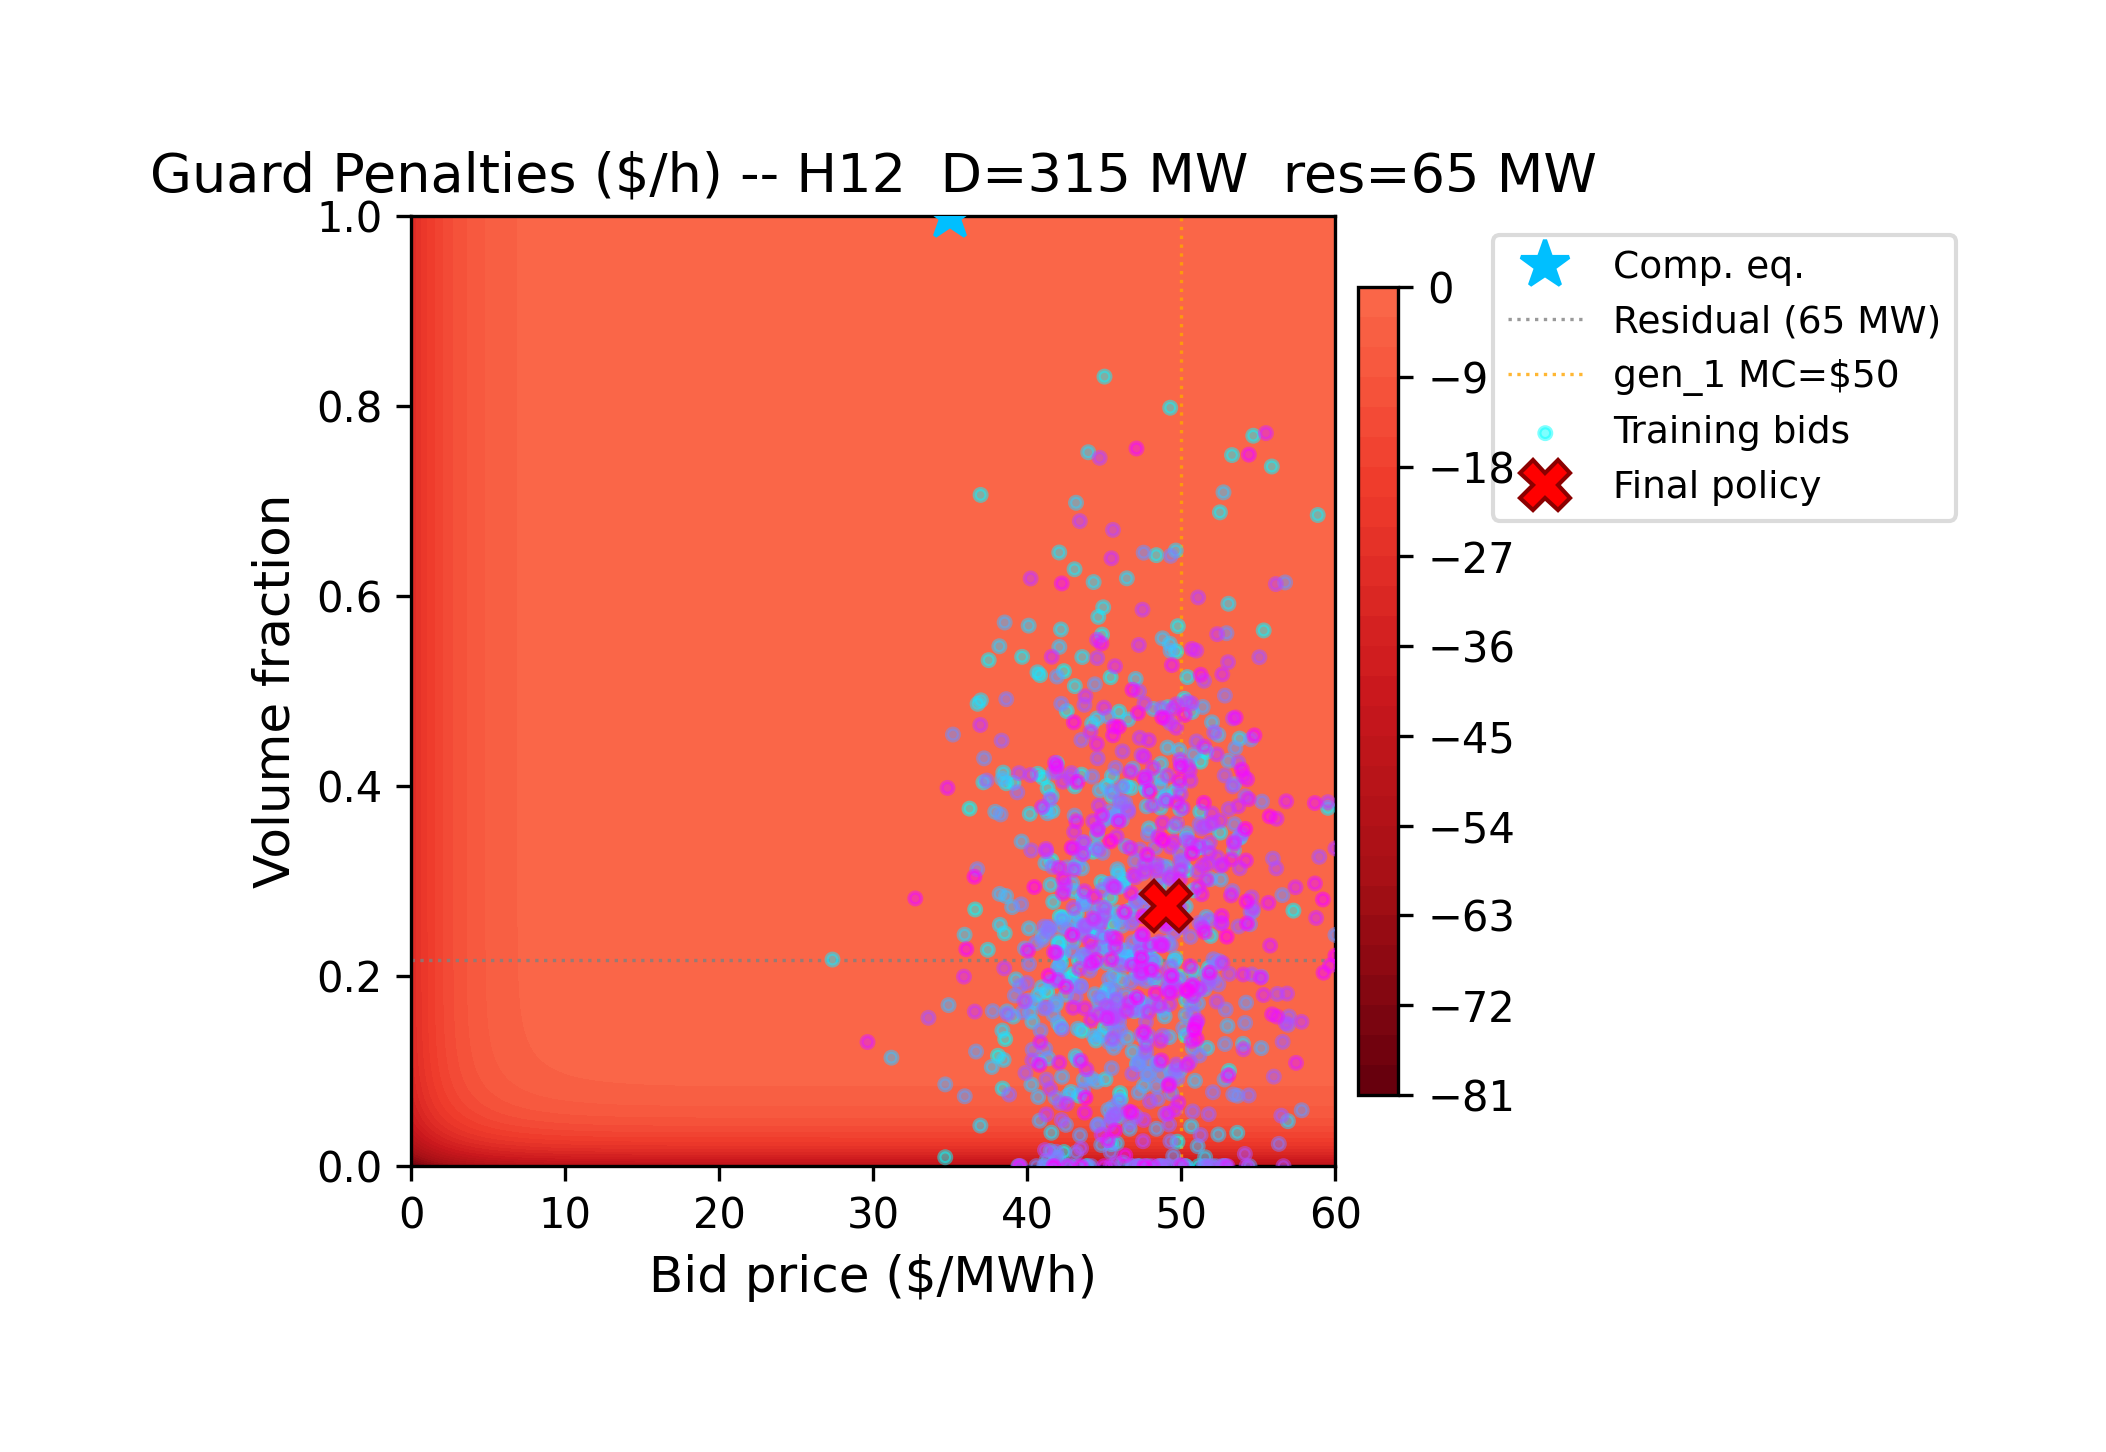

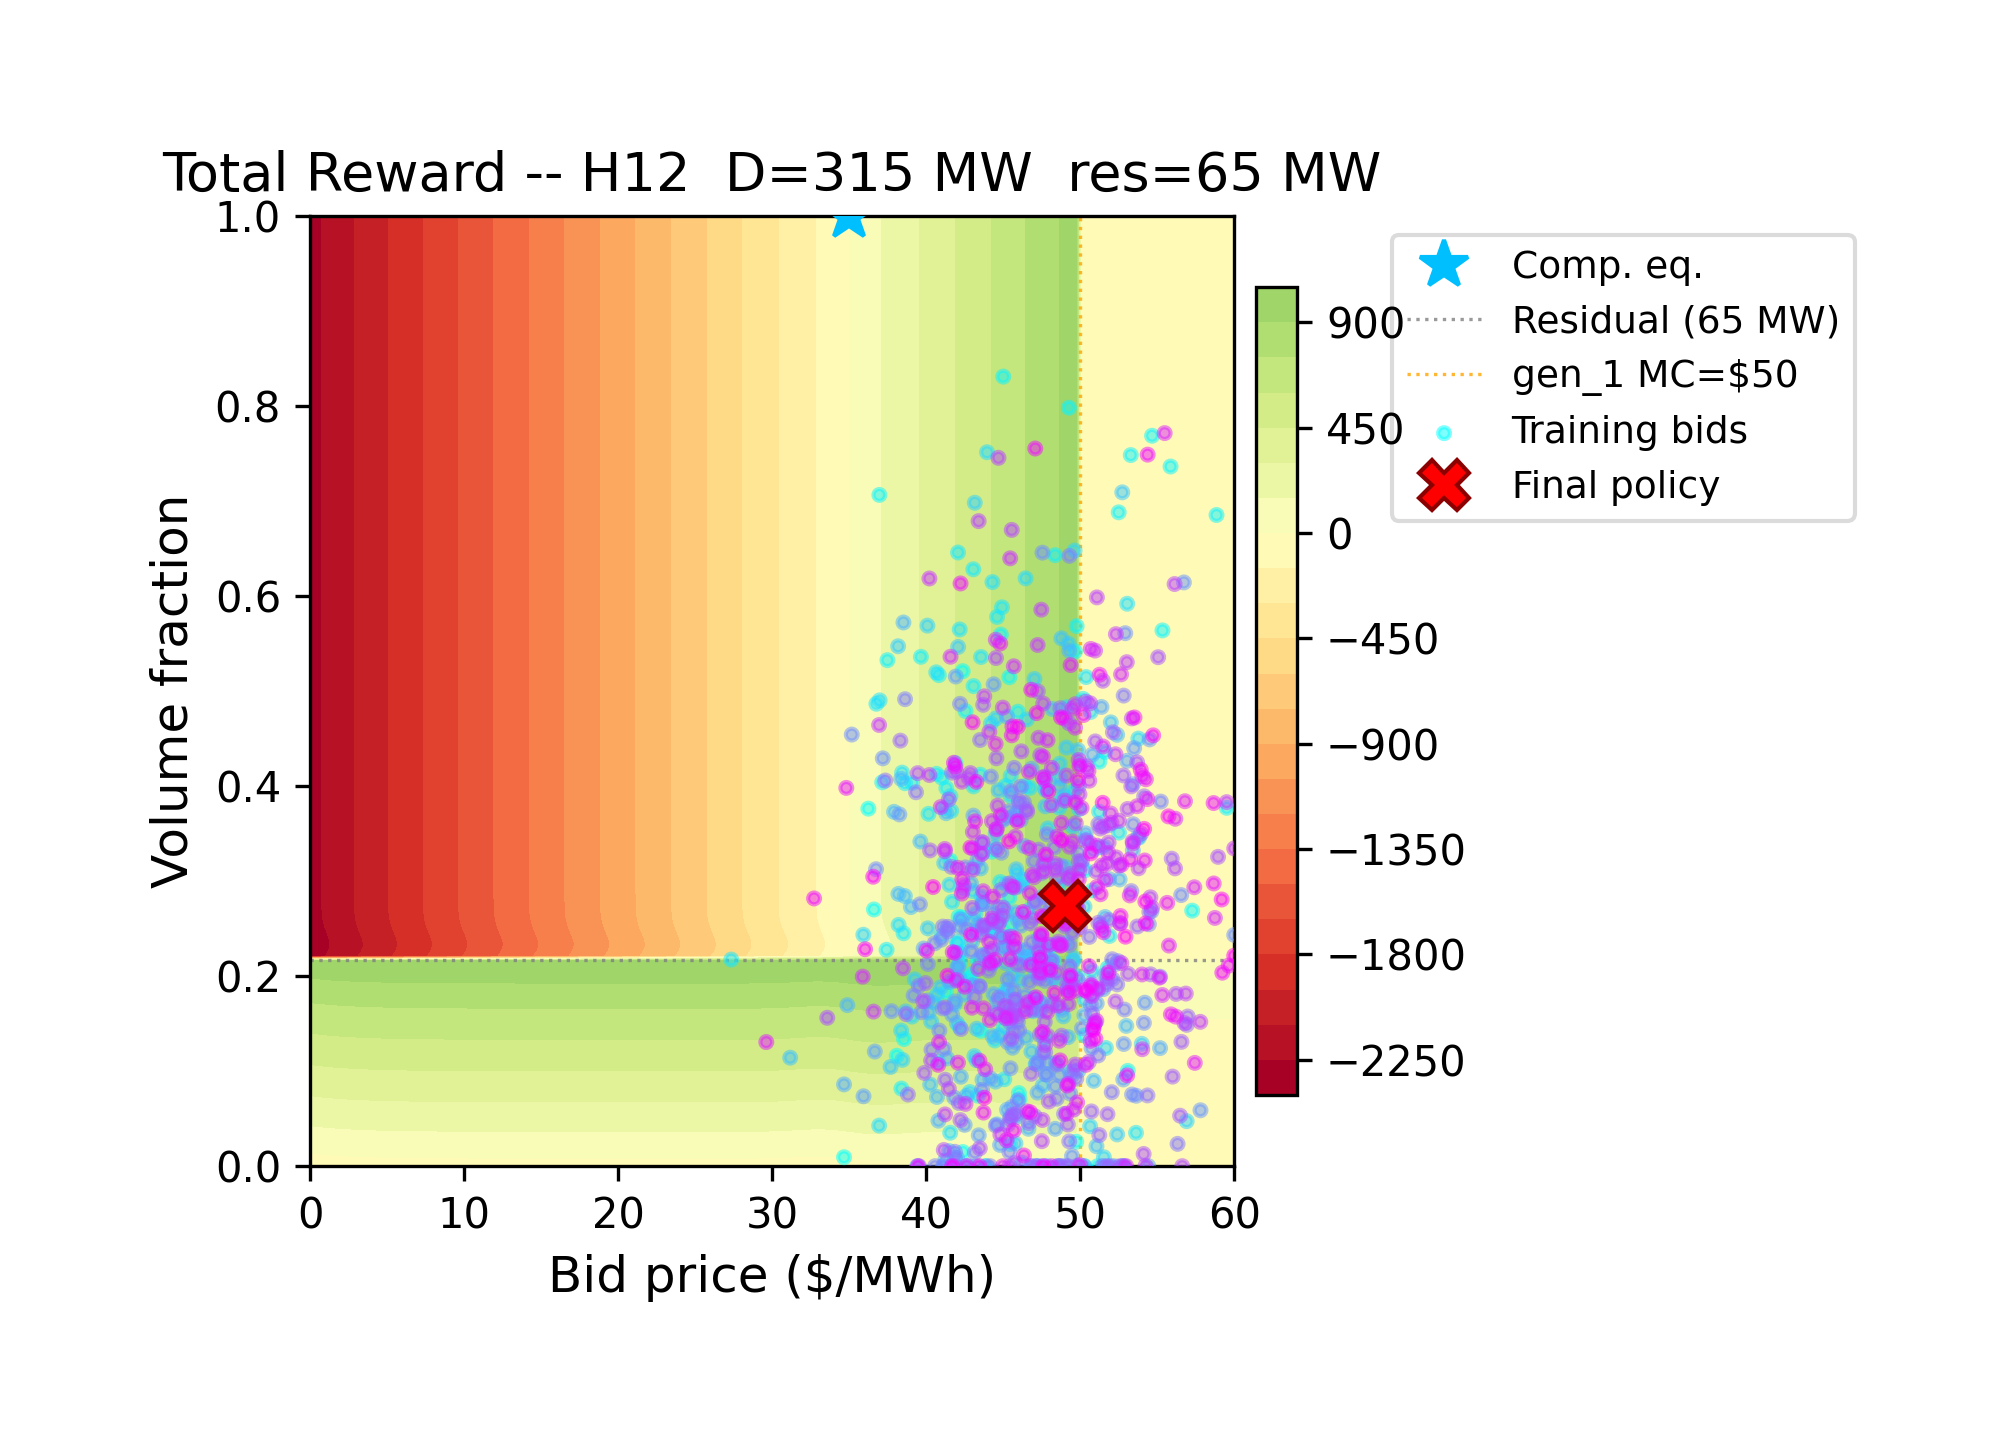

Saved: pres_profit/terrain/guards/reward_h12.png


In [69]:
# ── Analytical reward surface over the 2D action space (ProfitStrategy) ──────

_scen = all_scenarios[SCENARIO]
_pr  = _scen['profile']
_g0  = _scen['generators']['gen_0']
_g1  = _scen['generators']['gen_1']
_gs  = _scen['generators']['gen_slack_0']
_tr  = _scen['training']
_lc  = _tr.get('learning_config', _tr)

MC_0      = float(_g0['price'])
MC_1      = float(_g1['price'])
P_MAX_0   = float(_g0['p_max'])
P_MAX_1   = float(_g1['p_max'])
P_MAX_S   = float(_gs['p_max'])
PRICE_CAP = float(_g0.get('price_cap', float(_tr.get('max_bid_price', 100.0))))
BASE_LOAD = 90 + 100 + 125

# ── Terrain shaping parameters (Ricker wavelets, from scenario config) ───────
WAVELET_SCALE      = float(_lc.get('wavelet_scale', 100.0))
VOL_WAVELET_SCALE  = float(_lc.get('vol_wavelet_scale', 300.0))
PRICE_WAVELET_WIDTH = float(_lc.get('price_wavelet_width', 2.0))
VOL_WAVELET_WIDTH  = float(_lc.get('vol_wavelet_width', 5.0))
MC_MOUNTAIN_SCALE  = float(_lc.get('mc_mountain_scale', 300.0))
MC_MOUNTAIN_SIGMA  = float(_lc.get('mc_mountain_sigma', 3.0))
MC_MOUNTAIN_TAU    = float(_lc.get('mc_mountain_tau', 0.5))
VOL_PENALTY        = float(_lc.get('vol_penalty', 50.0))
VOL_STEEPNESS      = float(_lc.get('vol_steepness', 0.03))
PRICE_PENALTY      = float(_lc.get('price_penalty', 30.0))
PRICE_STEEPNESS    = float(_lc.get('price_steepness', 0.05))

_t = np.arange(24)
_raw = _pr['base'] + _pr['amplitude'] * np.sin(
    2 * np.pi * (_t - _pr['phase_shift']) / _pr['period'])
_profile  = np.clip(_raw, _pr['clip_min'], _pr['clip_max'])
_demand   = BASE_LOAD * _profile
_residual = np.maximum(0.0, _demand - P_MAX_S)

# Action space: price in [0, price_cap], volume fraction in [0, 1]
N = 200
price_ax = np.linspace(0.0, PRICE_CAP, N)
vol_ax   = np.linspace(0.0, 1.0, N)
PP, VV   = np.meshgrid(price_ax, vol_ax)
BID_VOL  = VV * P_MAX_0

def _reward_surface(hour):
    """ProfitStrategy reward: profit + Ricker wavelet shaping + guards."""
    D   = float(_demand[hour])
    res = max(0.0, D - P_MAX_S)

    # ── SCED dispatch model ──────────────────────────────────────────────
    A = PP <= MC_1
    enough_vol = BID_VOL >= res
    acc_A = np.where(A, np.where(enough_vol, res, BID_VOL), 0.0)
    lmp_A = np.where(A, np.where(enough_vol, PP, MC_1), 0.0)

    comp_fills = np.minimum(P_MAX_1, res)
    leftover   = np.maximum(0.0, res - comp_fills)
    acc_B = np.where(~A, np.minimum(BID_VOL, leftover), 0.0)
    lmp_B = np.where(~A, np.where(acc_B > 0.01, PP, MC_1), 0.0)

    dispatched_vol = acc_A + acc_B
    lmp = np.where(A, lmp_A, lmp_B)
    if res < 0.01:
        lmp = np.full_like(PP, 20.0)
        dispatched_vol = np.zeros_like(PP)

    # ── Profit ───────────────────────────────────────────────────────────
    profit = (lmp - MC_0) * dispatched_vol

    # Counterfactual price
    cf = MC_1 if res > 0.01 else 20.0

    # ── Fractions ────────────────────────────────────────────────────────
    vol_frac = BID_VOL / P_MAX_0

    # ── Terrain shaping (Ricker wavelets) ────────────────────────────────
    price_ceil_wavelet = np.zeros_like(PP)
    mc_floor_wavelet   = np.zeros_like(PP)
    vol_wavelet_arr    = np.zeros_like(PP)
    mc_mountain        = np.zeros_like(PP)
    pw = max(PRICE_WAVELET_WIDTH, 0.01)

    if res > 0.01:
        # PEAK: Ricker wavelets at all three edges
        resid_frac = min(res / P_MAX_0, 1.0)
        w_scale = WAVELET_SCALE * resid_frac

        # 1. Price ceiling wavelet — approach competitor MC from below
        #    No vol_frac scaling — price edges matter at all volume levels
        delta_ceil = (cf - PP) / pw
        price_ceil_wavelet = w_scale * delta_ceil * np.exp(-0.5 * delta_ceil**2)

        # 2. MC floor wavelet — stay above own MC
        delta_mc = (PP - MC_0) / pw
        mc_floor_wavelet = w_scale * delta_mc * np.exp(-0.5 * delta_mc**2)

        # 3. Volume wavelet — approach residual demand from below
        vw = max(VOL_WAVELET_WIDTH, 0.01)
        delta_vol = (res - BID_VOL) / vw
        vw_scale = VOL_WAVELET_SCALE * resid_frac
        vol_wavelet_arr = vw_scale * delta_vol * np.exp(-0.5 * delta_vol**2)
    else:
        # OFF-PEAK: MC mountain only (Gaussian safe harbor)
        sigma = max(MC_MOUNTAIN_SIGMA, 0.01)
        tau   = max(MC_MOUNTAIN_TAU, 0.01)
        mc_floor = 1.0 / (1.0 + np.exp(-(PP - MC_0) / tau))
        mc_decay = np.exp(-np.maximum(PP - MC_0, 0.0)**2 / (2.0 * sigma**2))
        mc_mountain = 2.0 * MC_MOUNTAIN_SCALE * mc_floor * mc_decay * vol_frac

    # ── Guards ───────────────────────────────────────────────────────────
    vol_guard = -VOL_PENALTY * np.exp(-vol_frac / VOL_STEEPNESS)
    price_frac = PP / PRICE_CAP
    price_guard = -PRICE_PENALTY * np.exp(-price_frac / PRICE_STEEPNESS)

    # ── Total reward ─────────────────────────────────────────────────────
    shaping = price_ceil_wavelet + mc_floor_wavelet + vol_wavelet_arr + mc_mountain
    reward = profit + shaping + vol_guard + price_guard

    return profit, reward, mc_mountain, price_ceil_wavelet, mc_floor_wavelet, vol_wavelet_arr, vol_guard, price_guard

# Training bids
_bids_df = bids_df.copy()

# Final policy bids
_fp_df = None
_fp_path = f'{RESULTS_DIR}/final_policy_bids.csv'
if os.path.exists(_fp_path):
    _fp_df = pd.read_csv(_fp_path, parse_dates=['timestamp'])
    _fp_df['hour'] = _fp_df['timestamp'].dt.hour

# ── Plot PLOT_HOUR only -- one figure per panel ───────────────────────────────
h = PLOT_HOUR
profit, reward, mc_mountain, price_ceil_w, mc_floor_w, vol_w, vol_guard, price_guard = _reward_surface(h)
res      = max(0.0, float(_demand[h]) - P_MAX_S)
vf_break = res / P_MAX_0 if P_MAX_0 > 0 else 0.0
hlabel   = f'H{h:02d}  D={_demand[h]:.0f} MW  res={res:.0f} MW'

panels = [
    (profit,      'RdYlGn', None, f'Profit ($/h) -- {hlabel}'),
    (price_ceil_w + mc_floor_w + vol_w + mc_mountain, 'RdYlGn', None, f'Wavelet Shaping ($/h) -- {hlabel}'),
    (vol_guard + price_guard, 'Reds_r', None, f'Guard Penalties ($/h) -- {hlabel}'),
    (reward,      'RdYlGn', None, f'Total Reward -- {hlabel}'),
]

for col, (data, cmap, vmin, title) in enumerate(panels):
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_W * 0.7))
    vmax = max(float(np.abs(data).max()), 0.01)

    if vmin is None:
        norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
        im = ax.contourf(price_ax, vol_ax, data, levels=30, cmap=cmap, norm=norm)
    else:
        im = ax.contourf(price_ax, vol_ax, data, levels=30, cmap=cmap,
                         vmin=vmin, vmax=vmax)

    fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    ax.set_title(title)
    ax.set_xlabel('Bid price ($/MWh)')
    ax.set_ylabel('Volume fraction')

    ax.plot(MC_0, 1.0, '*', color='deepskyblue', markersize=12, zorder=6,
            label=f'Comp. eq.')
    if vf_break > 0.01:
        ax.axhline(vf_break, color='gray', lw=0.8, ls=':', alpha=0.8,
                   label=f'Residual ({res:.0f} MW)')
    ax.axvline(MC_1, color='orange', lw=0.8, ls=':', alpha=0.8,
               label=f'gen_1 MC=${MC_1:.0f}')

    if _bids_df is not None:
        _hb = _bids_df[(_bids_df['hour'] == h) & (_bids_df['unit_id'] == FOCUS_AGENT)]
        if len(_hb) > 0:
            ax.scatter(
                _hb['bid_price'], _hb['bid_volume'] / P_MAX_0,
                c=_hb['episode'], cmap='cool', s=8, alpha=0.5, zorder=5,
                label='Training bids'
            )

    if _fp_df is not None:
        _fp_h = _fp_df[(_fp_df['hour'] == h) & (_fp_df['unit_id'] == FOCUS_AGENT)]
        for _, _fp_bid in _fp_h.iterrows():
            ax.plot(
                _fp_bid['bid_price'], _fp_bid['bid_volume'] / P_MAX_0,
                'X', color='red', markersize=12, zorder=8,
                markeredgecolor='darkred', markeredgewidth=1,
                label='Final policy'
            )
            break  # only label once

    ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.0), framealpha=0.7)
    plt.tight_layout()
    suffix = ['profit', 'terrain', 'guards', 'reward'][col]
    plt.savefig(f'{RESULTS_DIR}/pres_{suffix}_h{PLOT_HOUR:02d}.png', bbox_inches='tight')
    plt.show()

print(f'Saved: pres_profit/terrain/guards/reward_h{PLOT_HOUR:02d}.png')

## Chart 2 â€” Focus-Hour Bid Evolution (Price + Volume)

Shows how each RL agent's bids at `PLOT_HOUR` evolved across training episodes.
Price on the left axis, volume on the right. Reference lines show MC (dotted)
and the final noise-free policy bid (dashed).

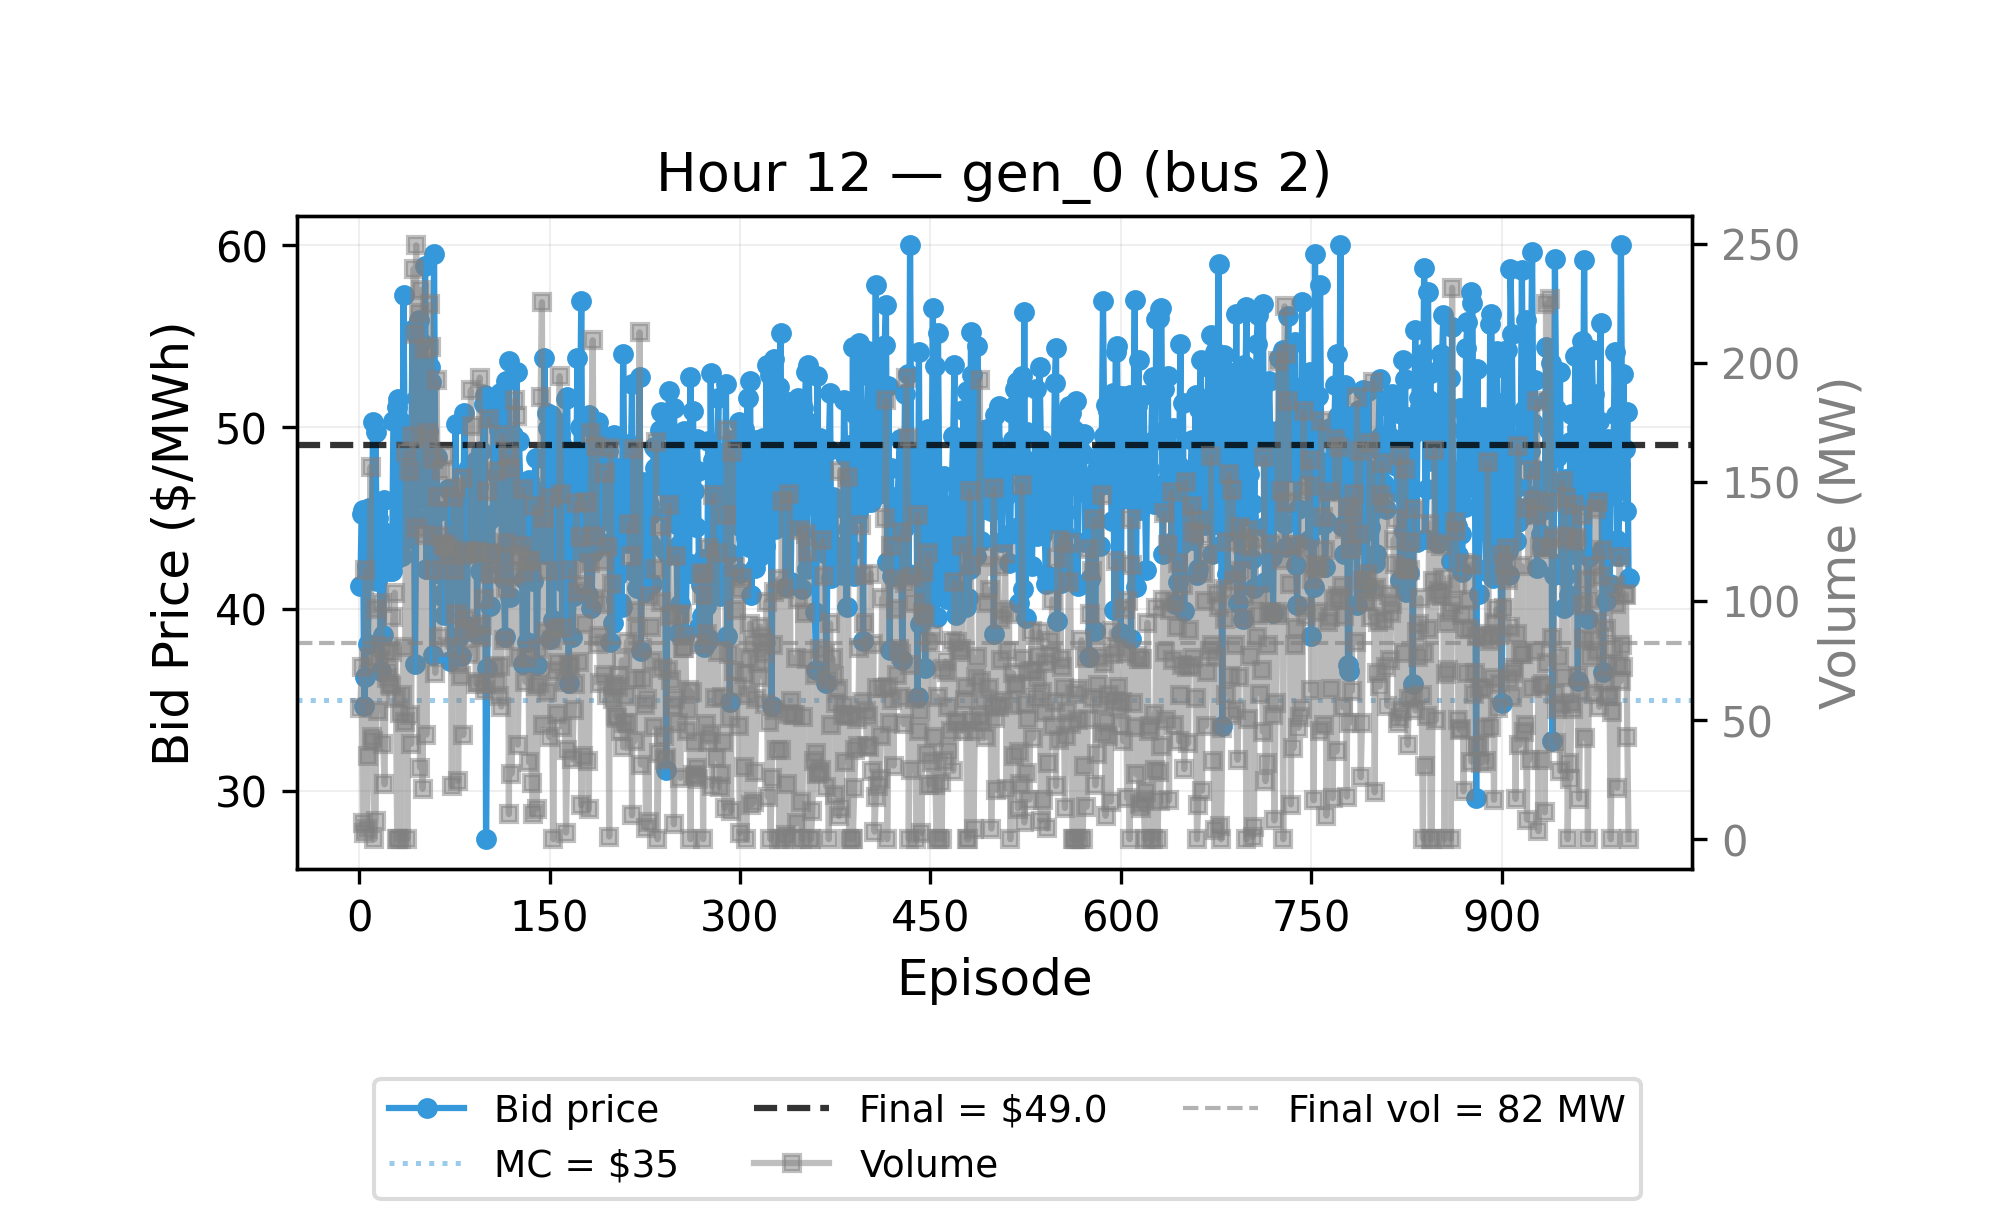

Saved: pres_bid_evolution_*_h12.png


In [70]:
# ── Focus-hour bid evolution: price + volume per episode ─────────────────────
# Load final policy bids for reference lines
_fp_path = f'{RESULTS_DIR}/final_policy_bids.csv'
_fp_bids = None
if os.path.exists(_fp_path):
    _fp_bids = pd.read_csv(_fp_path, parse_dates=['timestamp'])
    _fp_bids['hour'] = _fp_bids['timestamp'].dt.hour

# Filter to PLOT_HOUR only
hour_bids = primary_bids[primary_bids['hour'] == PLOT_HOUR].copy()
episodes = sorted(hour_bids['episode'].unique())

# One figure per RL agent — each is FIG_W wide
for unit in RL_AGENTS:
    color = UNIT_COLORS[unit]
    gen_hour = hour_bids[hour_bids['unit_id'] == unit]

    ep_data = gen_hour.groupby('episode').agg(
        price_mean=('bid_price', 'mean'),
        price_min=('bid_price', 'min'),
        price_max=('bid_price', 'max'),
        vol_mean=('bid_volume', 'mean'),
        vol_min=('bid_volume', 'min'),
        vol_max=('bid_volume', 'max'),
    )

    fig, ax = plt.subplots(figsize=(FIG_W, FIG_W * 0.55))

    # Price on primary axis
    ax.fill_between(ep_data.index, ep_data['price_min'], ep_data['price_max'],
                    alpha=0.12, color=color)
    ax.plot(ep_data.index, ep_data['price_mean'], '-o', color=color,
            label=f'{BID_LABEL} price')

    # MC reference (dotted)
    ax.axhline(MC[unit], color=color, linestyle=':', alpha=0.5, linewidth=1.2,
               label=f'MC = ${MC[unit]:.0f}')

    # Final policy price reference (dashed)
    fp_h = pd.DataFrame()
    fp_vol = 0
    if _fp_bids is not None:
        fp_h = _fp_bids[(_fp_bids['unit_id'] == unit) & (_fp_bids['hour'] == PLOT_HOUR)]
        if len(fp_h) > 0:
            fp_price = fp_h['bid_price'].mean()
            fp_vol = fp_h['bid_volume'].mean()
            ax.axhline(fp_price, color='black', linestyle='--', linewidth=1.5,
                       alpha=0.8, label=f'Final = ${fp_price:.1f}')

    ax.set_ylabel(f'{BID_LABEL} Price ($/MWh)')
    ax.set_xlabel('Episode')
    ax.set_title(f'Hour {PLOT_HOUR} \u2014 {unit} (bus {gen_bus[unit]})')
    ax.grid(True, alpha=0.2)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

    # Volume on secondary axis
    ax2 = ax.twinx()
    ax2.fill_between(ep_data.index, ep_data['vol_min'], ep_data['vol_max'],
                     alpha=0.08, color='gray')
    ax2.plot(ep_data.index, ep_data['vol_mean'], '-s', color='gray',
             alpha=0.5, label='Volume')
    ax2.set_ylabel('Volume (MW)', color='gray')
    ax2.tick_params(axis='y', labelcolor='gray')

    # Final policy volume reference
    if len(fp_h) > 0:
        ax2.axhline(fp_vol, color='gray', linestyle='--', linewidth=1,
                    alpha=0.6, label=f'Final vol = {fp_vol:.0f} MW')

    # Combined legend — below the chart in reserved space
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    fig.legend(lines1 + lines2, labels1 + labels2,
               loc='lower center', ncol=3, framealpha=0.7)
    fig.subplots_adjust(bottom=0.22)

    plt.savefig(f'{RESULTS_DIR}/pres_bid_evolution_{unit}_h{PLOT_HOUR:02d}.png', bbox_inches='tight')
    plt.show()

print(f'Saved: pres_bid_evolution_*_h{PLOT_HOUR:02d}.png')

## Chart 3 â€” LMP & Dispatch (All Hours)

From original cell 21.

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
INFO:learning_runner:Added generator 'gen_peaker_0': bus=1, p_max=50.0, price=60.0
INFO:learning_runner:Generator overrides applied: gen_0($35, 300MW), gen_1($50, 270MW), gen_slack_0($20, 250MW), gen_peaker_0($60, 50MW)
INFO:learning_runner:Line overrides applied: line_0(250MW), line_1(250MW), line_2(150MW), line_3(300MW), line_4(150MW), line_5(250MW), line_6(250MW), line_7(250MW), line_8(250MW)
Running SCED (168 orders, 24 periods)...
INFO:clearing.sced_clearing:Solving Egret SCED (relaxed=True)...
Calculating PTDF Matrix Factorization
INFO:egret:Calculating PTDF Matrix Factorization
Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP has 1119 rows; 1032 cols; 2060 nonzeros
Coefficient ranges:
  Matrix  [2e-01, 6e+03]
  Cost    [1e+00, 1e+0

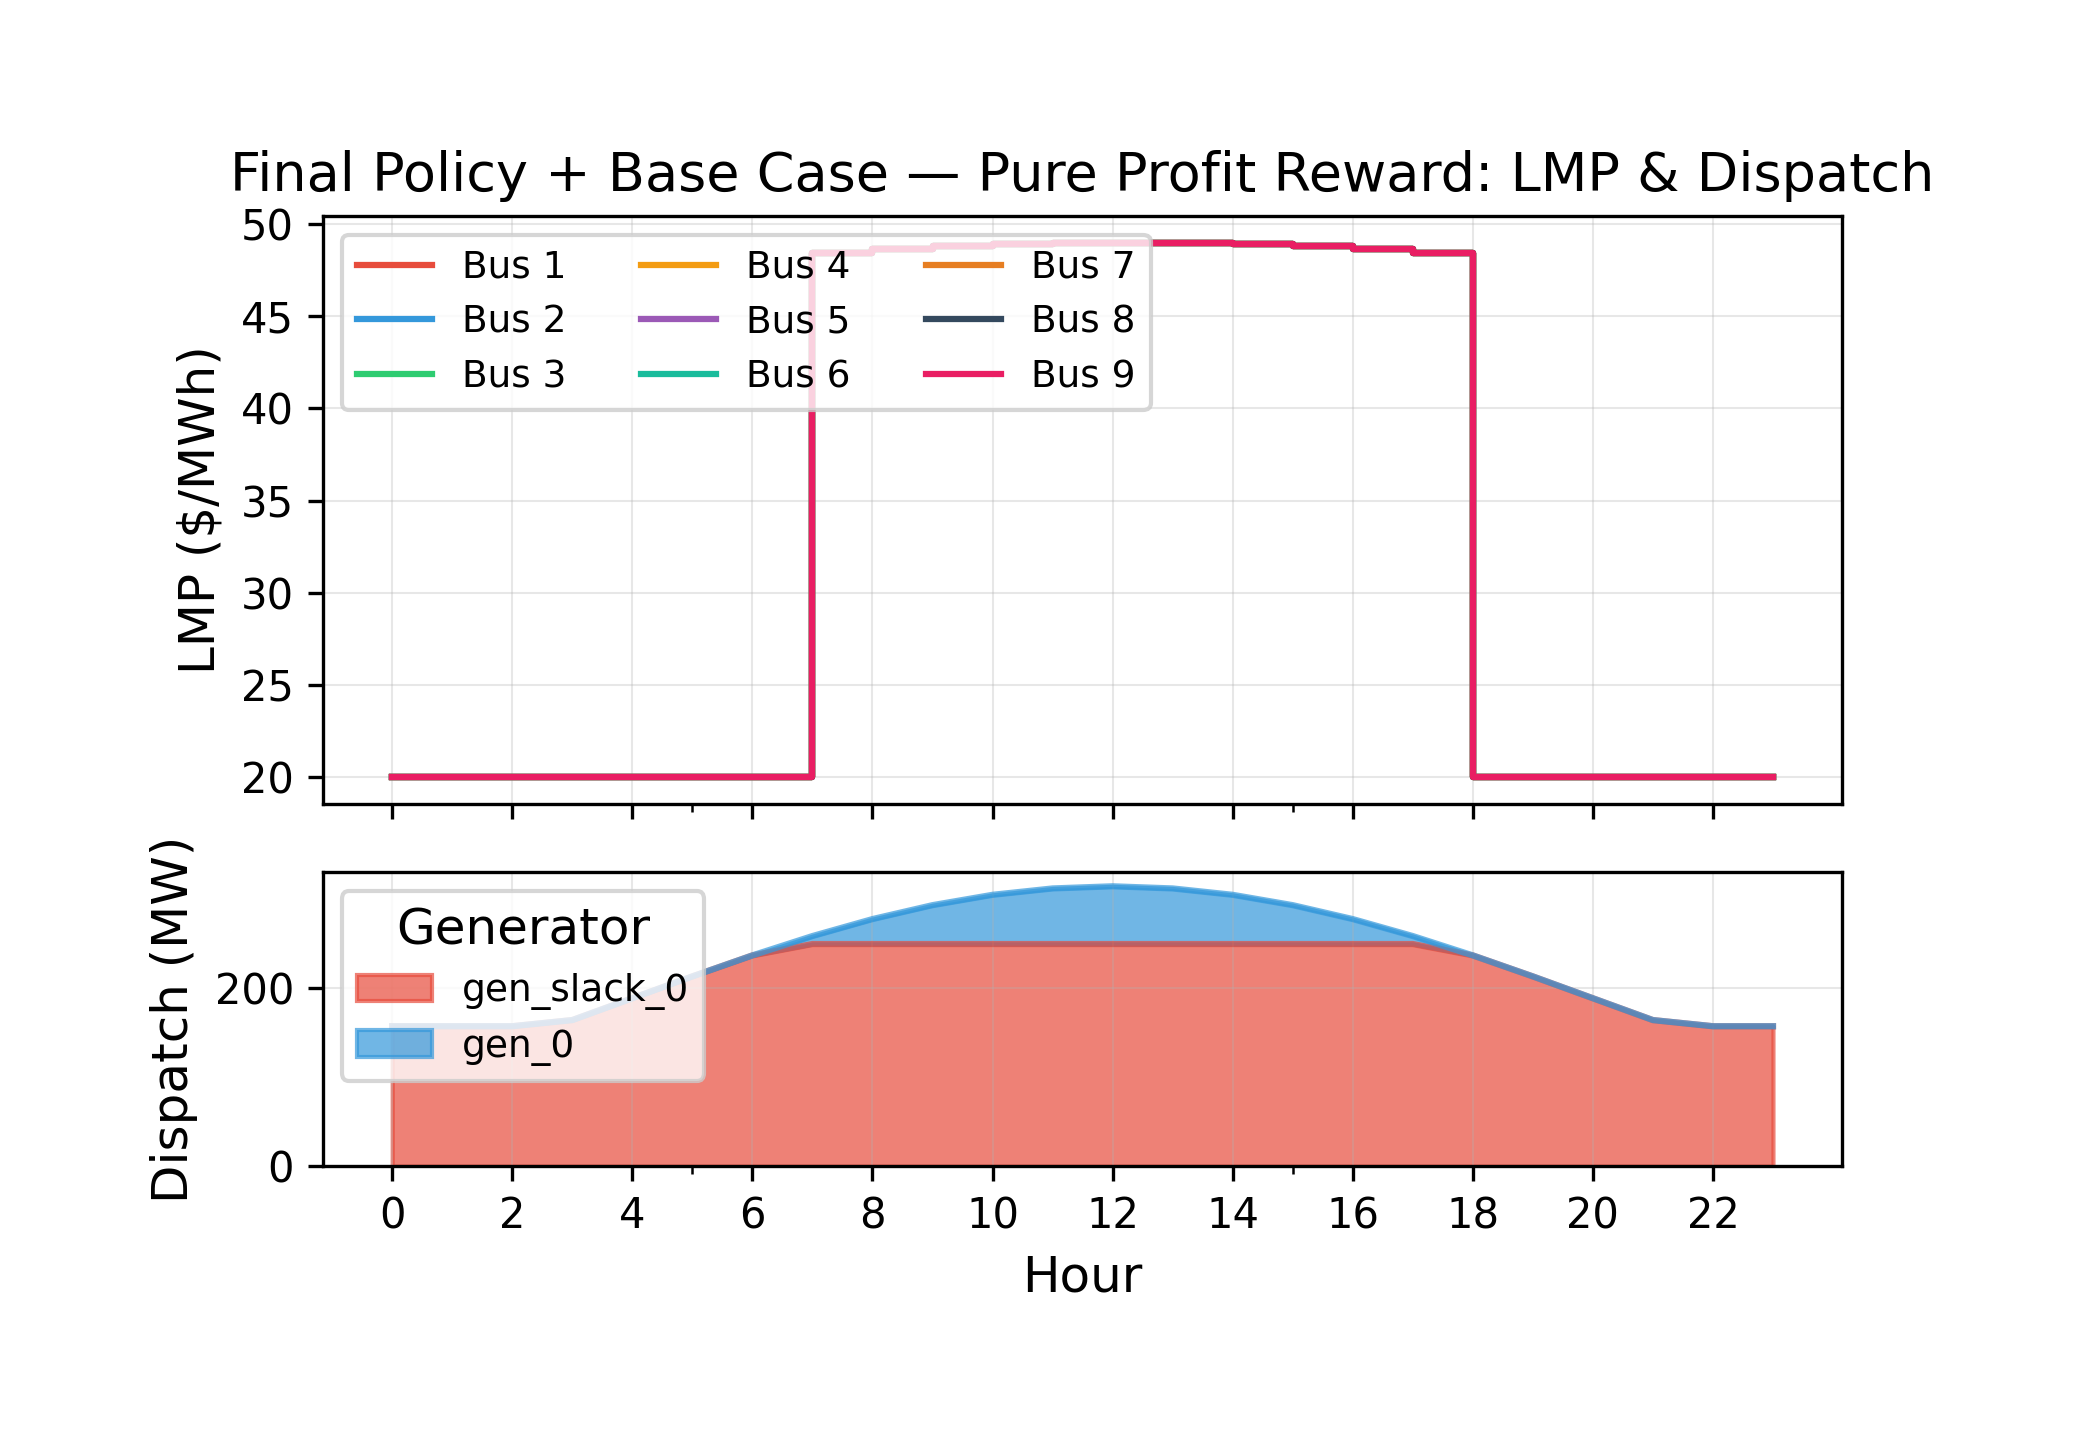

Saved: ../testbed_results/rl_matd3/pres_lmp_dispatch.png


In [71]:
# â”€â”€ SCED Re-run (same as inspect_rl_results cells 18-20) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
from learning_runner import _apply_generator_overrides, _apply_line_overrides

_pcfg      = scenario_cfg.get('profile', {})
periods    = scenario_cfg.get('periods', 24)
base        = _pcfg.get('base',        0.6)
amplitude   = _pcfg.get('amplitude',   0.4)
phase_shift = _pcfg.get('phase_shift', 4)
period_len  = _pcfg.get('period',      32)
clip_min    = _pcfg.get('clip_min',    0.5)
clip_max    = _pcfg.get('clip_max',    1.0)

_network_rerun = build_ieee9_network(start='2025-01-01', periods=periods, profile_cfg=_pcfg)
_apply_generator_overrides(_network_rerun, scenario_cfg.get('generators', {}))
_apply_line_overrides(_network_rerun, line_overrides)
network = _network_rerun

_gen_df_rerun  = network.generators.copy()
_gen_df_rerun.rename(columns={'bus': 'node', 'p_nom': 'max_power'}, inplace=True)
_loads_df_rerun = network.loads.copy()
_loads_df_rerun.rename(columns={'bus': 'node', 'p_set': 'min_power'}, inplace=True)

grid_data_rerun = {
    'buses':      network.buses,
    'lines':      network.lines,
    'generators': _gen_df_rerun,
    'loads':      _loads_df_rerun,
}

# Final policy bids
_policy_bids_path = f'{RESULTS_DIR}/final_policy_bids.csv'
try:
    final_policy_bids = pd.read_csv(_policy_bids_path, parse_dates=['timestamp'])
    final_policy_bids['hour'] = final_policy_bids['timestamp'].dt.hour
    fp_types = set(final_policy_bids['bid_type'].unique())
    if fp_types == {'pmin'}:
        final_policy_bids['bid_type'] = 'single'
except FileNotFoundError:
    final_policy_bids = None
    print('WARNING: final_policy_bids not found')

# Build orderbook
_orderbook_rerun = []
market_products  = []
for _i, _ts in enumerate(network.snapshots):
    _start = _ts.to_pydatetime()
    _end   = _start + timedelta(hours=1)
    market_products.append((_start, _end, None))
    for _gen_name, _gen in _gen_df_rerun.iterrows():
        if final_policy_bids is not None and _gen_name in RL_GENERATORS:
            _h = _ts.hour
            _fp = final_policy_bids[
                (final_policy_bids['unit_id'] == _gen_name) &
                (final_policy_bids['hour'] == _h)
            ]
            if not _fp.empty:
                _bid_price = float(_fp.iloc[0]['bid_price'])
                _bid_vol   = float(_fp.iloc[0]['bid_volume'])
            else:
                _bid_price = float(_gen['marginal_cost'])
                _bid_vol   = float(_gen['max_power'])
        else:
            _bid_price = float(_gen['marginal_cost'])
            _bid_vol   = float(_gen['max_power'])
        _orderbook_rerun.append({
            'start_time': _start, 'end_time': _end, 'only_hours': None,
            'price': _bid_price, 'volume': _bid_vol,
            'node': _gen['node'], 'unit_id': _gen_name,
            'bid_id': f'{_gen_name}_{_i}',
        })
    for _load_name in network.loads.index:
        if _load_name in network.loads_t.p_set.columns:
            _demand_val = float(network.loads_t.p_set.at[_ts, _load_name])
        else:
            _demand_val = float(_loads_df_rerun.at[_load_name, 'min_power'])
        _orderbook_rerun.append({
            'start_time': _start, 'end_time': _end, 'only_hours': None,
            'price': 1000.0, 'volume': -_demand_val,
            'node': network.loads.at[_load_name, 'bus'],
            'unit_id': _load_name, 'bid_id': f'{_load_name}_{_i}',
        })

print(f'Running SCED ({len(_orderbook_rerun)} orders, {len(market_products)} periods)...')
accepted, rejected, meta, flows = clear_sced(
    _orderbook_rerun, market_products, grid_data_rerun, solver='highs',
)
print(f'SCED complete: {len(accepted)} accepted, {len(rejected)} rejected')

# â”€â”€ Load profile â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
load_profile = np.array([
    np.clip(base + amplitude * np.sin(2 * np.pi * (h - phase_shift) / period_len), clip_min, clip_max)
    for h in range(periods)
])

# â”€â”€ LMP + Dispatch pivot â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
acc_df_best = pd.DataFrame(accepted)
acc_df_best['hour'] = acc_df_best['start_time'].dt.hour

lmp_records = []
for m in meta:
    hour = m['product_start'].hour
    for bus, lmp in m.get('bus_lmps', {}).items():
        lmp_records.append({'hour': hour, 'bus': bus, 'lmp': lmp})
lmp_final = pd.DataFrame(lmp_records).drop_duplicates(subset=['hour', 'bus'])
lmp_pivot = lmp_final.pivot(index='hour', columns='bus', values='lmp').sort_index()

all_buses = sorted(_network_rerun.buses.index.tolist(), key=lambda x: int(x))
active_buses = sorted([str(b) for b in lmp_pivot.columns.tolist()], key=lambda x: int(x))
palette_idx = 0
bus_color_map = {}
for b in all_buses:
    if b in active_buses:
        bus_color_map[b] = BUS_PALETTE[palette_idx % len(BUS_PALETTE)]
        palette_idx += 1
    else:
        bus_color_map[b] = TRANSIT_COLOR

# â”€â”€ Dual panel: LMP + dispatch â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(FIG_W, FIG_W * 0.7), sharex=True,
                                gridspec_kw={'height_ratios': [2, 1]})

for bus in active_buses:
    if bus in lmp_pivot.columns:
        ax1.step(lmp_pivot.index, lmp_pivot[bus], where='post',
                 label=f'Bus {bus}', color=bus_color_map[bus])

ax1.set_ylabel('LMP ($/MWh)')
ax1.set_title(f'Final Policy + {scenario_name}: LMP & Dispatch')
ax1.legend(loc='upper left', ncol=3)
ax1.grid(True, alpha=0.3)

supply_acc = acc_df_best[acc_df_best['volume'] > 0].copy()
disp_pivot = supply_acc.pivot_table(
    index='hour', columns='unit_id', values='accepted_volume',
    aggfunc='sum', fill_value=0,
)
gen_order = sorted(gen_mc.keys(), key=lambda g: gen_mc[g])
cols = [c for c in gen_order if c in disp_pivot.columns]
gen_colors = {g: bus_color_map.get(gen_bus[g], '#888') for g in gen_order}

disp_pivot[cols].plot.area(ax=ax2, alpha=0.7, color=[gen_colors[c] for c in cols])
ax2.set_ylabel('Dispatch (MW)')
ax2.set_xlabel('Hour')
ax2.legend(title='Generator', loc='upper left')
ax2.set_xticks(range(0, 24, 2))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/pres_lmp_dispatch.png', bbox_inches='tight')
plt.show()
print(f'Saved: {RESULTS_DIR}/pres_lmp_dispatch.png')

## Chart 4 â€” Network Topology & Circlize (Focus Hour)

From original cell 25.  Produces both the network diagram and the circlize chord diagram.

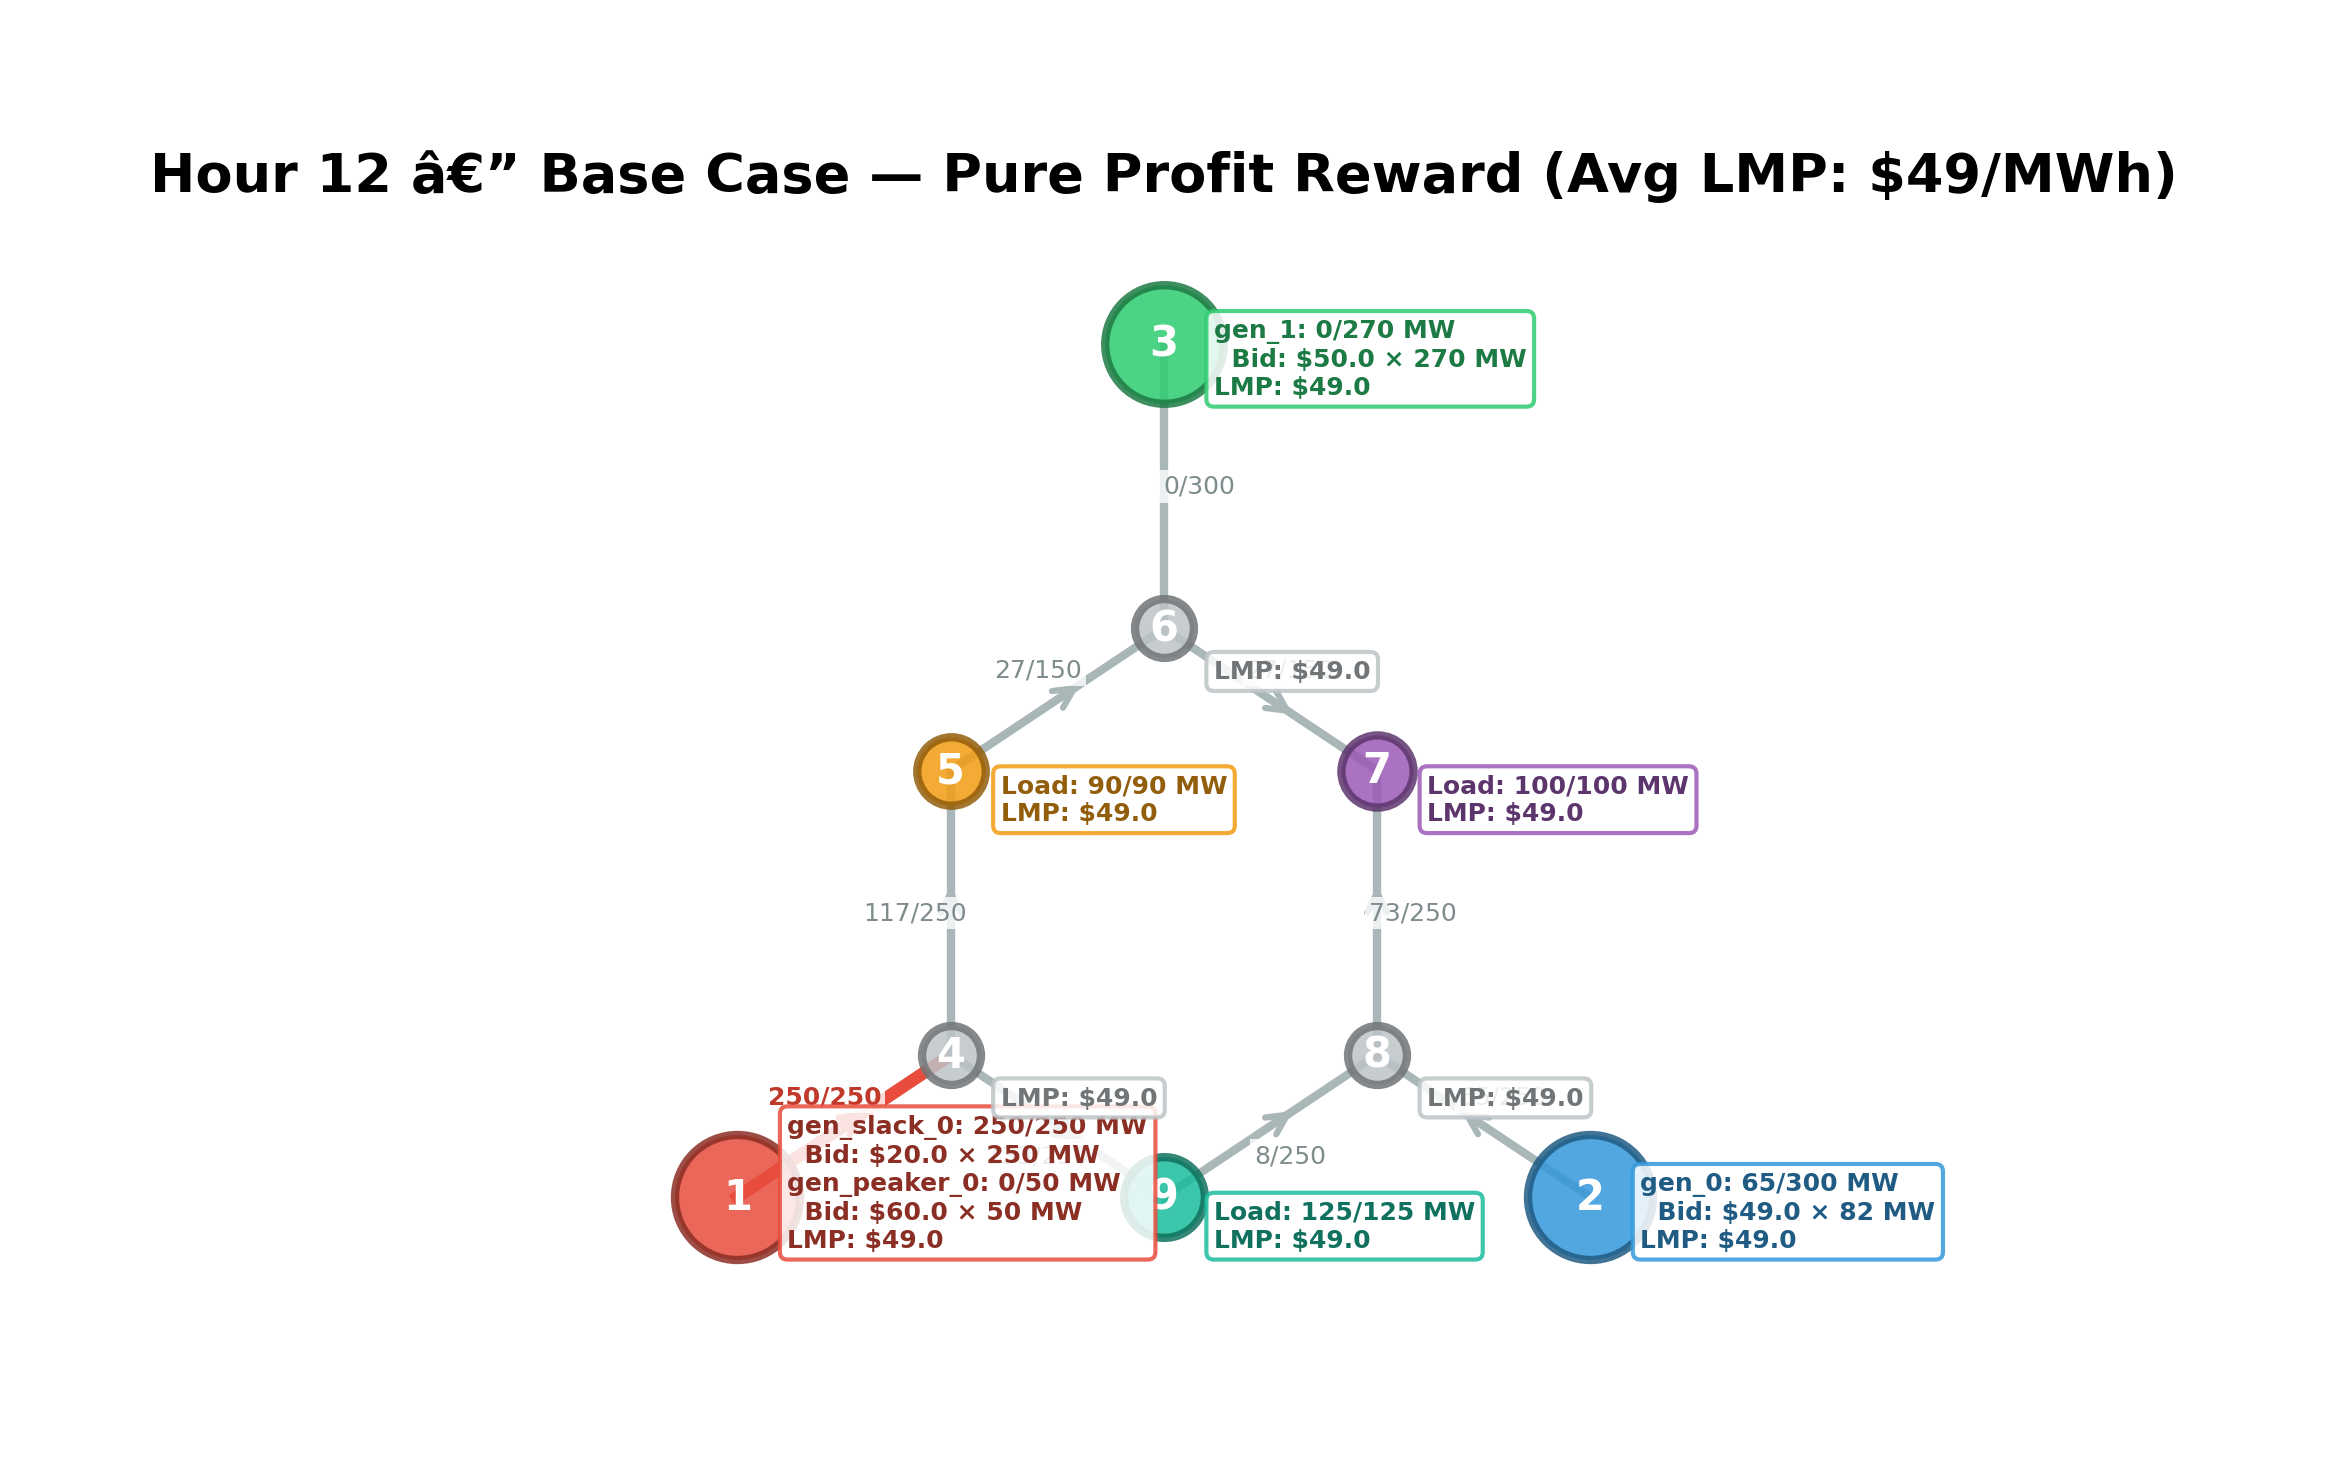

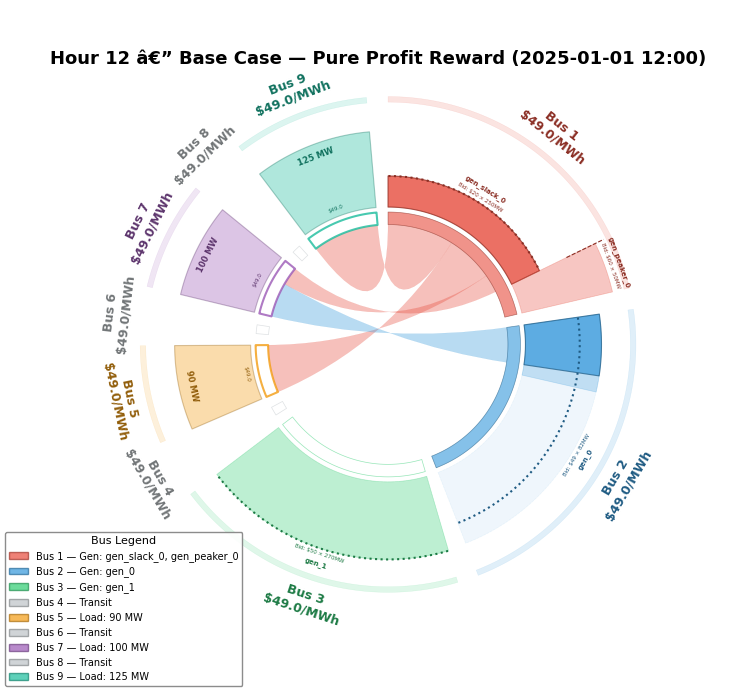

Saved: pres_network_h12.png, pres_circlize_h12.png


In [72]:
# â”€â”€ plot_hour helpers (from original cell 21) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
def get_hour_data(hour_idx):
    """Extract supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps for a given hour."""
    t_start = market_products[hour_idx][0]
    _capacities = dict(gen_capacity)
    for sg_name, sg in scenario_cfg.get('generators', {}).items():
        if sg_name not in _capacities:
            _capacities[sg_name] = sg.get('p_max', 0)

    supply_by_bus = {}
    for o in accepted + rejected:
        if o['start_time'] != t_start or o['volume'] <= 0:
            continue
        bus = o['node']
        if bus not in supply_by_bus:
            supply_by_bus[bus] = []
        supply_by_bus[bus].append({
            'unit_id': o['unit_id'], 'price': o['price'],
            'volume': o['volume'], 'accepted_volume': o.get('accepted_volume', 0),
            'capacity': _capacities.get(o['unit_id'], o['volume']),
        })

    all_gen_names = set(_gen_df.index) | set(scenario_cfg.get('generators', {}).keys())
    for gn in all_gen_names:
        bus = gen_bus.get(gn)
        if not bus:
            continue
        if bus not in supply_by_bus:
            supply_by_bus[bus] = []
        existing = {g['unit_id'] for g in supply_by_bus[bus]}
        if gn not in existing:
            supply_by_bus[bus].append({
                'unit_id': gn, 'price': gen_mc.get(gn, 0),
                'volume': 0, 'accepted_volume': 0,
                'capacity': _capacities.get(gn, 0),
            })
    for bus in supply_by_bus:
        supply_by_bus[bus].sort(key=lambda g: g['price'])

    demand_by_bus = {}
    demand_served_by_bus = {}
    for o in accepted + rejected:
        if o['start_time'] != t_start or o['volume'] >= 0:
            continue
        bus = o['node']
        demand_by_bus[bus] = demand_by_bus.get(bus, 0) + abs(o['volume'])
        demand_served_by_bus[bus] = demand_served_by_bus.get(bus, 0) + abs(o.get('accepted_volume', 0))

    bus_lmps = meta[hour_idx].get('bus_lmps', {})
    hour_line_flows = {}
    for (line_name, t_idx), flow_mw in flows.items():
        if t_idx == hour_idx:
            hour_line_flows[line_name] = flow_mw
    return supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps, hour_line_flows


def plot_hour_pres(hour_idx):
    """Plot network topology + circlize for a given hour (presentation sized)."""
    supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps, hour_line_flows = get_hour_data(hour_idx)
    t_start = market_products[hour_idx][0]
    colors = assign_bus_colors(all_buses, supply_by_bus, demand_by_bus)
    flow_list = compute_ptdf_flows(network, supply_by_bus, demand_by_bus)
    m = meta[hour_idx]
    avg_lmp = m['price']

    fig_topo, ax_topo = plot_network_topology(
        network, supply_by_bus, demand_by_bus,
        bus_colors=colors, bus_lmps=bus_lmps,
        demand_served_by_bus=demand_served_by_bus,
        line_flows=hour_line_flows if hour_line_flows else None,
        title=f'Hour {hour_idx:02d} â€” {scenario_name} (Avg LMP: ${avg_lmp:.0f}/MWh)',
    )
    fig_topo.set_size_inches(FIG_W, FIG_W * 0.8)
    fig_topo.savefig(f'{RESULTS_DIR}/pres_network_h{hour_idx:02d}.png', bbox_inches='tight')
    plt.show()

    fig_circ = plot_nodal_circlize(
        supply_by_bus, demand_by_bus, all_buses,
        flows=flow_list, clearing_price=avg_lmp, bus_lmps=bus_lmps,
        title=f'Hour {hour_idx:02d} â€” {scenario_name} ({t_start.strftime("%Y-%m-%d %H:%M")})',
        bus_colors=colors, gen_marginal_costs=gen_mc,
    )
    fig_circ.set_size_inches(FIG_W, FIG_W)
    fig_circ.savefig(f'{RESULTS_DIR}/pres_circlize_h{hour_idx:02d}.png', bbox_inches='tight')
    plt.show()

    print(f'Saved: pres_network_h{hour_idx:02d}.png, pres_circlize_h{hour_idx:02d}.png')

plot_hour_pres(PLOT_HOUR)